In [2]:
import pickle, sys
sys.path.append(r"D:\Resplan")   # lets Python find the authors' helper code

with open(r"D:\Resplan\ResPlan.pkl", "rb") as f:
    plans = pickle.load(f)

print("Container type:", type(plans).__name__, "| number of plans:", len(plans))

first = plans[0] if isinstance(plans, list) else next(iter(plans.values()))
print("One plan is a:", type(first).__name__)

if isinstance(first, dict):
    for key, value in first.items():
        print(f"  {key:15} -> {type(value).__name__}")

Container type: list | number of plans: 17000
One plan is a: dict
  balcony         -> MultiPolygon
  bathroom        -> MultiPolygon
  bedroom         -> MultiPolygon
  door            -> MultiPolygon
  garden          -> MultiPolygon
  inner           -> MultiPolygon
  parking         -> MultiPolygon
  pool            -> MultiPolygon
  wall            -> MultiPolygon
  window          -> MultiPolygon
  front_door      -> Polygon
  id              -> int
  kitchen         -> Polygon
  land            -> MultiPolygon
  net_area        -> float64
  area            -> float
  neighbor        -> tuple
  living          -> Polygon
  wall_depth      -> float
  graph           -> Graph


In [5]:
import pandas as pd
from collections import Counter

# 1. Which parts does every plan have, and which are sometimes missing?
key_counts = Counter(k for p in plans for k in p.keys())
print("How many plans have each part:")
for k, n in key_counts.most_common():
    print(f"  {k:16} {n:6}  ({n/len(plans):.0%})")

# 2. Check every plan for problems
rows = []
for i, p in enumerate(plans):
    empty = invalid = 0
    for k, g in p.items():
        if not hasattr(g, "is_empty"):   # skip numbers, ids, graphs
            continue
        if g.is_empty:
            empty += 1
        elif not g.is_valid:
            invalid += 1
    inner = p.get("inner")
    rows.append({
        "idx": i, "id": p.get("id"),
        "area": p.get("area"), "net_area": p.get("net_area"),
        "wall_depth": p.get("wall_depth"),
        "empty_shapes": empty, "broken_shapes": invalid,
        "no_outline": inner is None or inner.is_empty,
        "n_rooms": p["graph"].number_of_nodes() if p.get("graph") is not None else 0,
    })
df = pd.DataFrame(rows)

# 3. Summary
print("\n--- PROBLEMS FOUND ---")
print("Duplicate ids:               ", df["id"].duplicated().sum())
print("Plans with broken shapes:    ", (df.broken_shapes > 0).sum())
print("Plans with empty shapes:     ", (df.empty_shapes > 0).sum())
print("Plans with no outline:       ", df.no_outline.sum())
print("Plans with no rooms in graph:", (df.n_rooms == 0).sum())
print("\n--- SIZE STATISTICS ---")
print(df[["area", "net_area", "wall_depth", "n_rooms"]].describe().round(1))

How many plans have each part:
  bathroom          17000  (100%)
  door              17000  (100%)
  garden            17000  (100%)
  inner             17000  (100%)
  parking           17000  (100%)
  wall              17000  (100%)
  id                17000  (100%)
  land              17000  (100%)
  net_area          17000  (100%)
  area              17000  (100%)
  neighbor          17000  (100%)
  living            17000  (100%)
  wall_depth        17000  (100%)
  graph             17000  (100%)
  pool              16999  (100%)
  bedroom           16997  (100%)
  front_door        16995  (100%)
  window            16950  (100%)
  kitchen           16875  (99%)
  balcony           13066  (77%)
  storage            1781  (10%)
  stair               685  (4%)
  area_change_sqft    683  (4%)

--- PROBLEMS FOUND ---
Duplicate ids:                0
Plans with broken shapes:     862
Plans with empty shapes:      17000
Plans with no outline:        0
Plans with no rooms in graph: 0

---

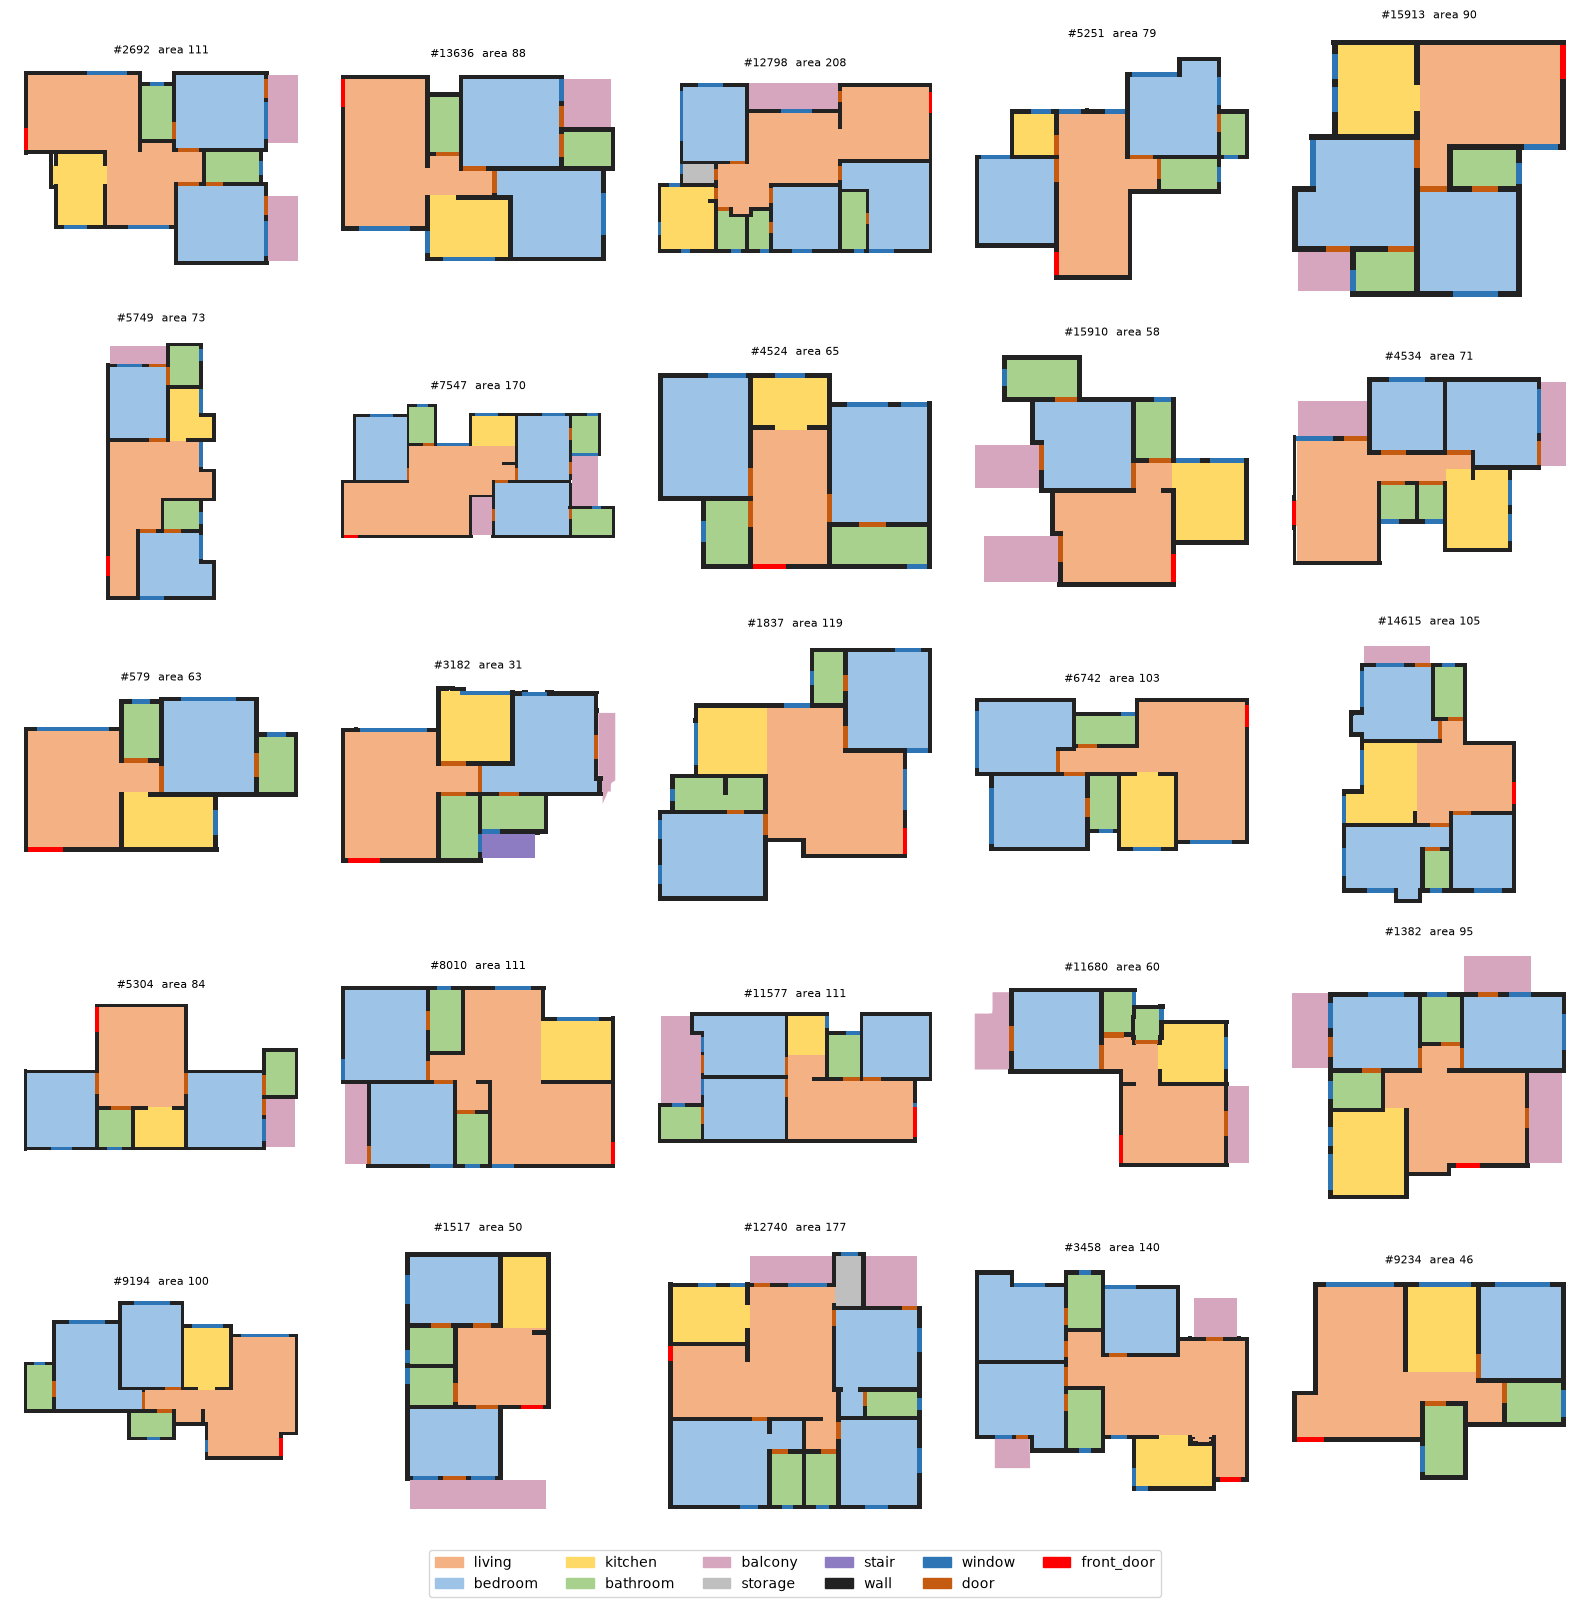

In [6]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import random

COLORS = {
    "living": "#f4b183", "bedroom": "#9dc3e6", "kitchen": "#ffd966",
    "bathroom": "#a9d18e", "balcony": "#d5a6bd", "storage": "#bfbfbf",
    "stair": "#8e7cc3", "wall": "#222222", "window": "#2e75b6",
    "door": "#c55a11", "front_door": "#ff0000",
}

def draw_plan(p, ax, title=""):
    for key, color in COLORS.items():
        g = p.get(key)
        if g is None or not hasattr(g, "is_empty") or g.is_empty:
            continue
        parts = g.geoms if hasattr(g, "geoms") else [g]
        for poly in parts:
            if poly.geom_type == "Polygon":
                x, y = poly.exterior.xy
                ax.fill(x, y, color=color, linewidth=0)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, fontsize=8)

def show_random(n=25):
    picks = random.sample(range(len(plans)), n)
    cols = 5
    fig, axes = plt.subplots((n + cols - 1) // cols, cols, figsize=(16, 16))
    for ax, i in zip(axes.flat, picks):
        draw_plan(plans[i], ax, f"#{i}  area {plans[i]['area']:.0f}")
    legend = [Patch(color=c, label=k) for k, c in COLORS.items()]
    fig.legend(handles=legend, loc="lower center", ncol=6)
    plt.tight_layout(rect=[0, 0.04, 1, 1])
    plt.show()

show_random()

No front_door :    5 plans -> [1073, 4593, 6604, 8870, 10126]
No bedroom    :    3 plans -> [5636, 14965, 15300]
No window     :   51 plans -> [78, 454, 708, 935, 1227, 1790, 1915, 1961, 1978, 2232, 3435, 3504, 3726, 3753, 3896, 3978, 5013, 5716, 5964, 7049, 7206, 7298, 7431, 8133, 8627, 8767, 8778, 9239, 9258, 9269] ...
No kitchen    :  125 plans -> [58, 105, 287, 297, 493, 500, 563, 710, 800, 1073, 1353, 1369, 1432, 1625, 1784, 1797, 1836, 1948, 2175, 2199, 2429, 3128, 3176, 3503, 3601, 3665, 3730, 3888, 3930, 3975] ...


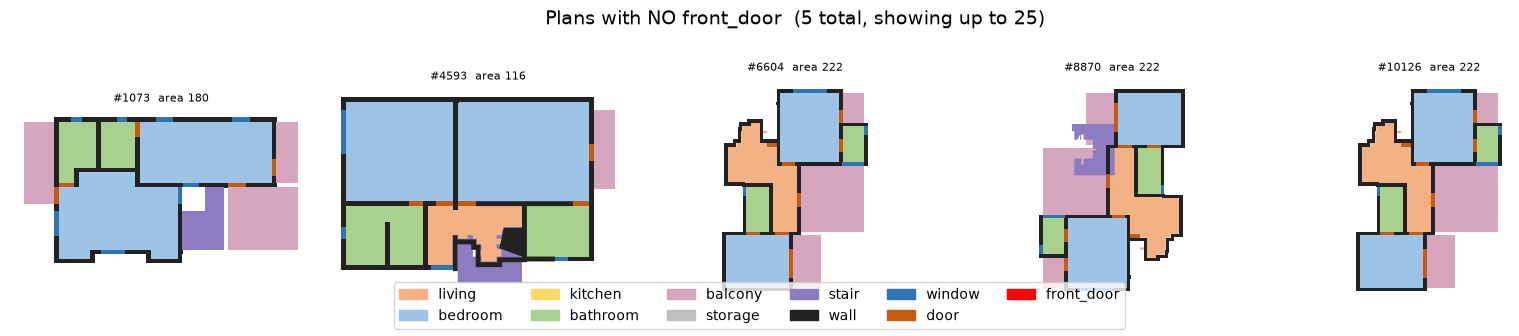

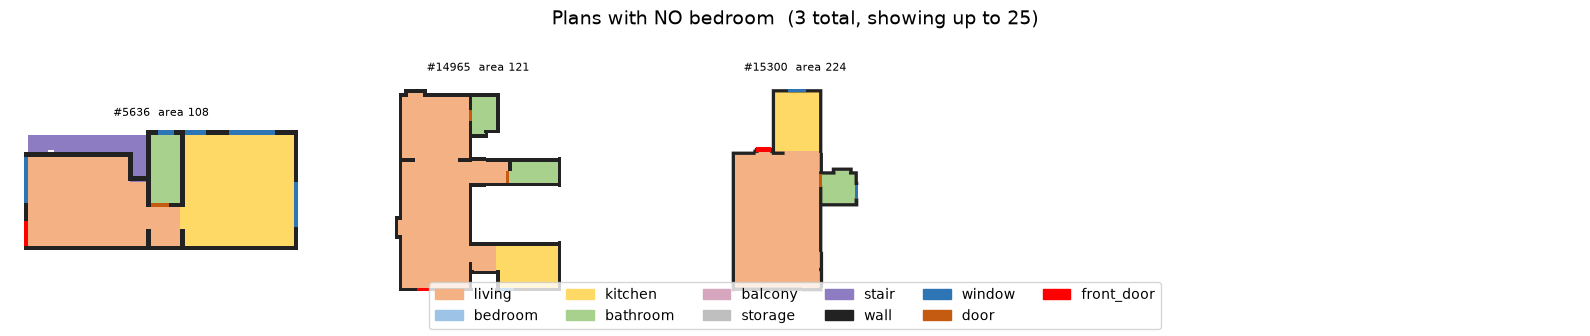

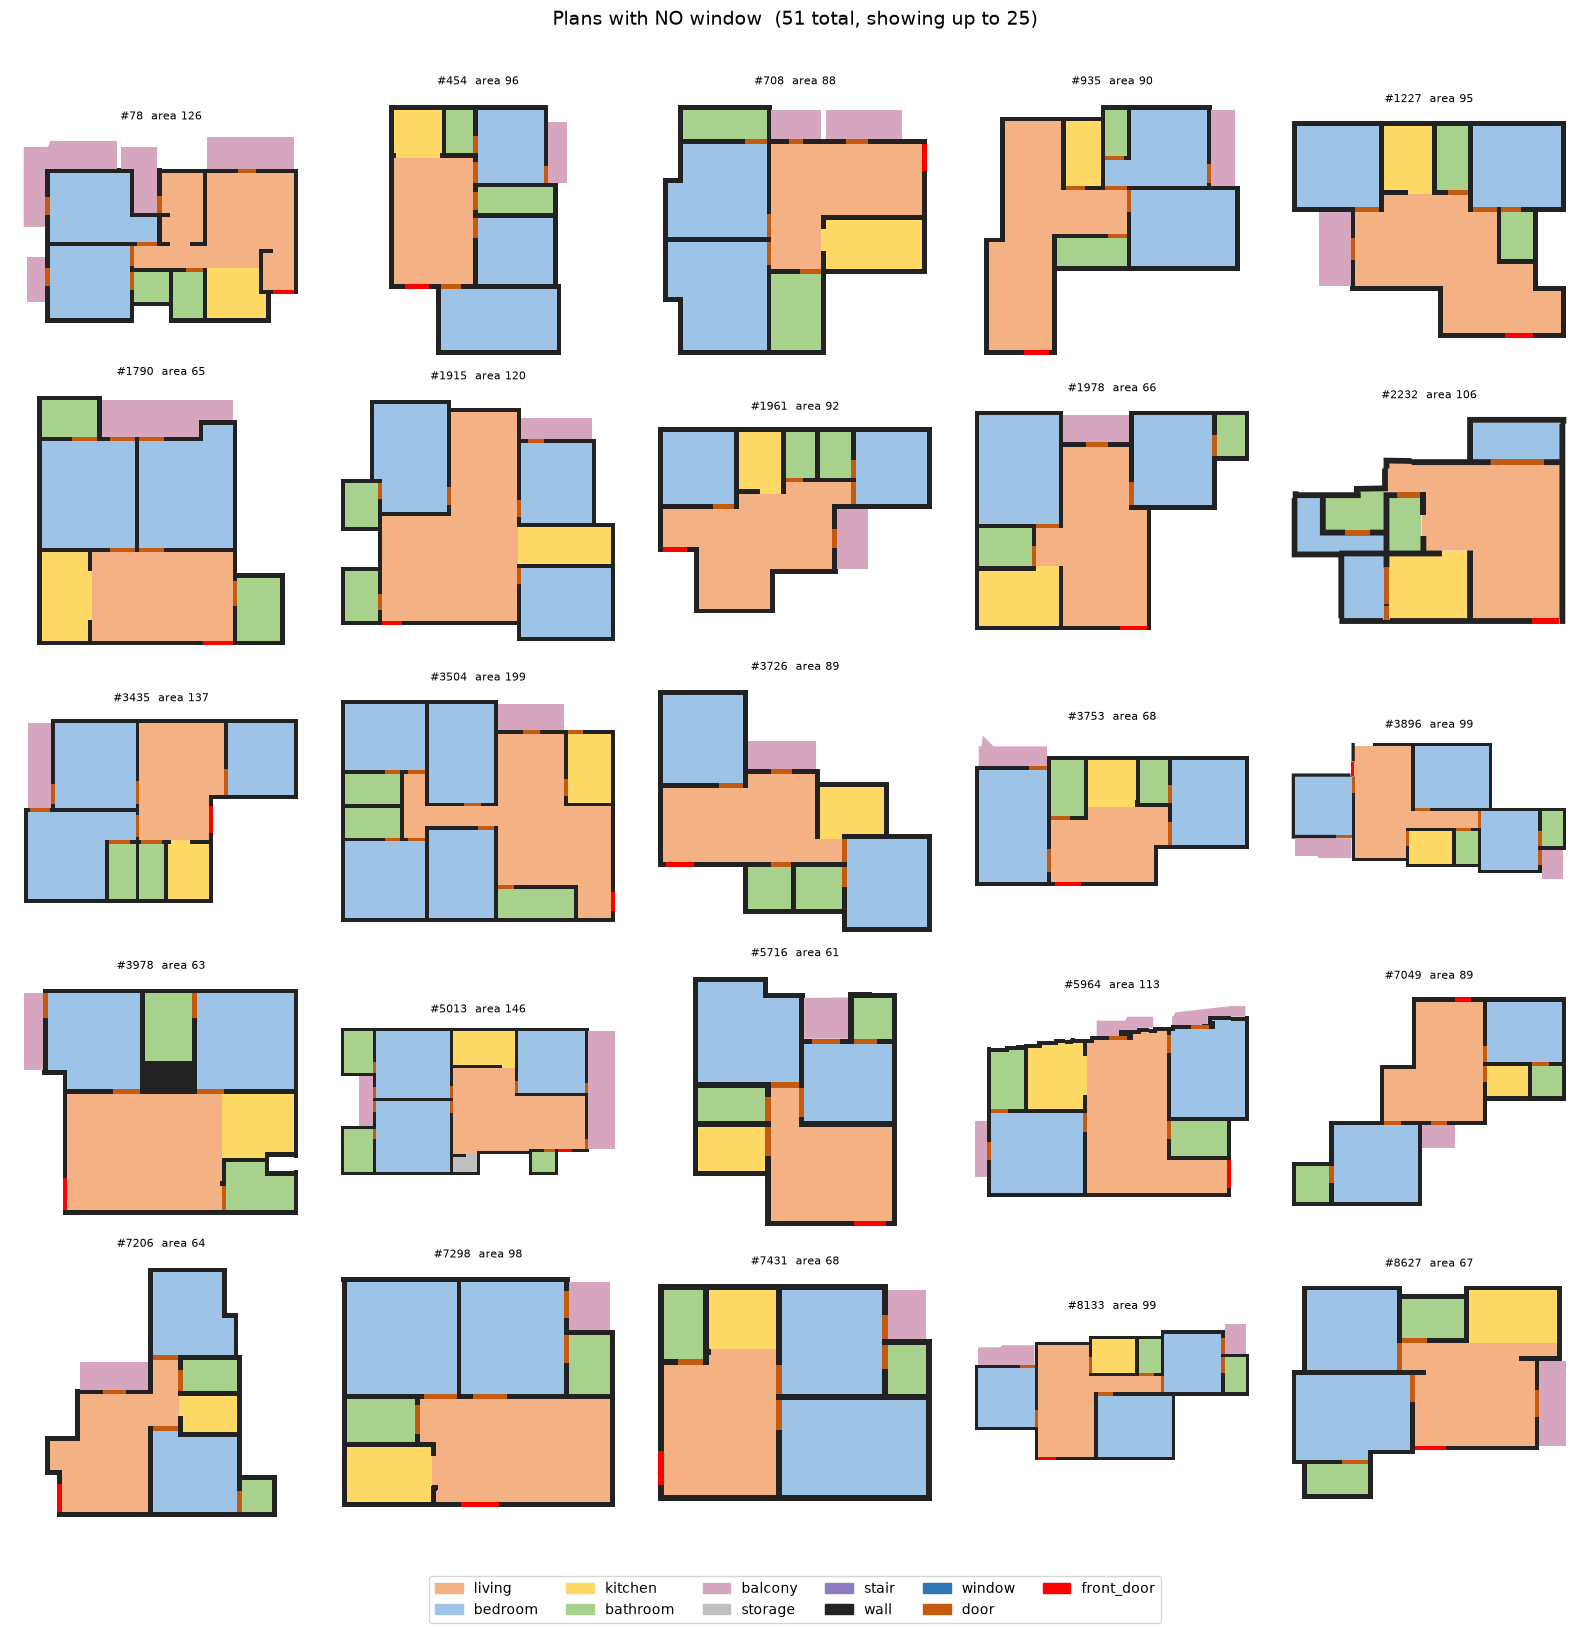

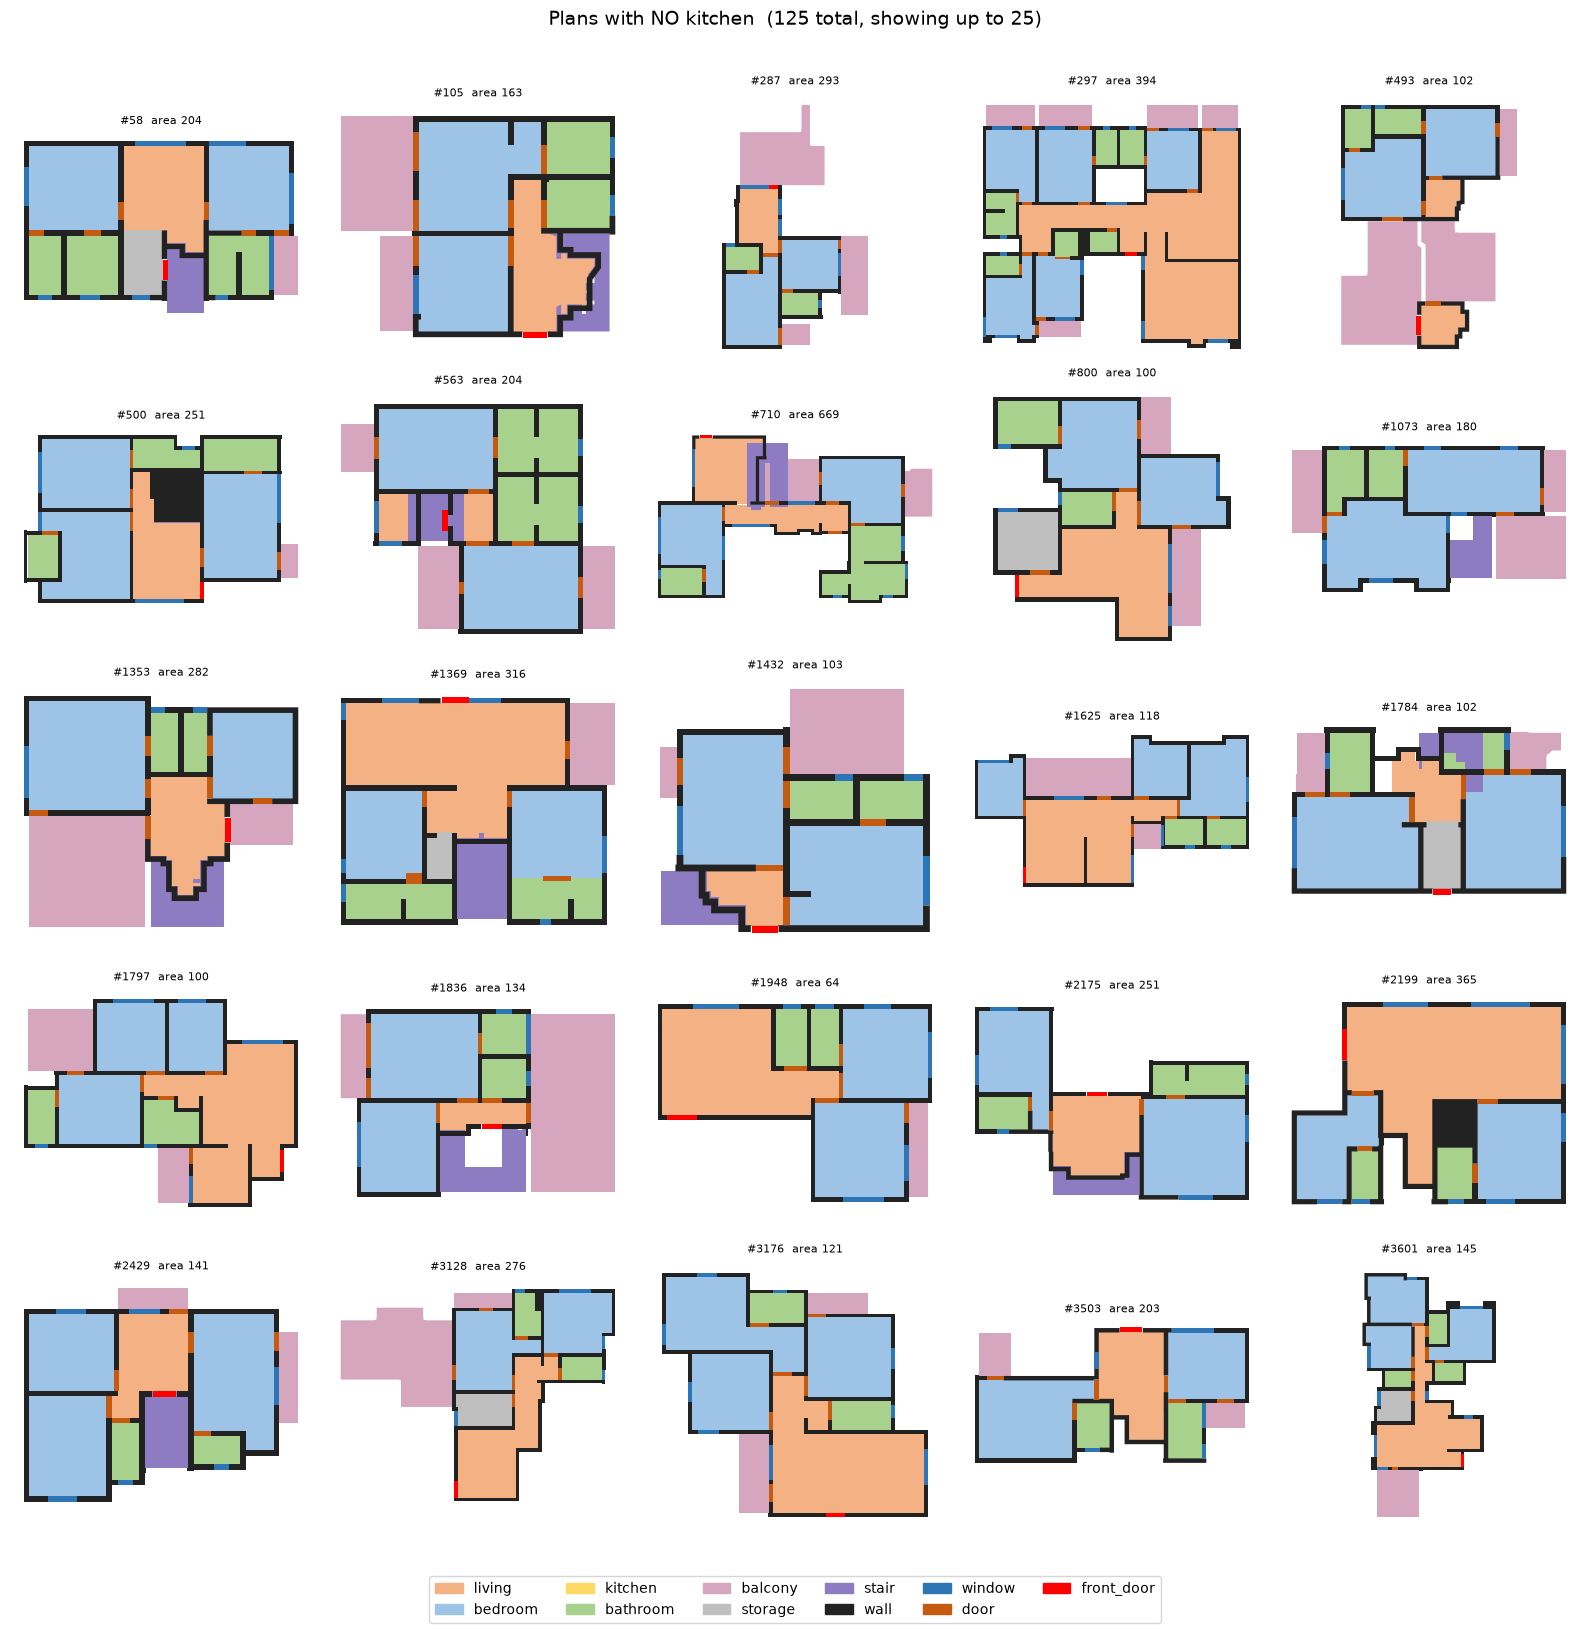

In [7]:
# Find plans where a part is missing (absent or empty)
def missing(key):
    out = []
    for i, p in enumerate(plans):
        g = p.get(key)
        if g is None or (hasattr(g, "is_empty") and g.is_empty):
            out.append(i)
    return out

suspects = {k: missing(k) for k in ["front_door", "bedroom", "window", "kitchen"]}

for k, idx in suspects.items():
    print(f"No {k:11}: {len(idx):4} plans -> {idx[:30]}{' ...' if len(idx) > 30 else ''}")

def show_list(idx, title, max_n=25):
    idx = idx[:max_n]
    cols = 5
    n_rows = (len(idx) + cols - 1) // cols
    fig, axes = plt.subplots(n_rows, cols, figsize=(16, 3.3 * n_rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, idx):
        draw_plan(plans[i], ax, f"#{i}  area {plans[i]['area']:.0f}")
    legend = [Patch(color=c, label=k) for k, c in COLORS.items()]
    fig.legend(handles=legend, loc="lower center", ncol=6)
    fig.suptitle(title, fontsize=14)
    plt.tight_layout(rect=[0, 0.05, 1, 0.97])
    plt.show()

for k, idx in suspects.items():
    show_list(idx, f"Plans with NO {k}  ({len(idx)} total, showing up to 25)")

In [8]:
def has(p, key):
    g = p.get(key)
    return g is not None and hasattr(g, "is_empty") and not g.is_empty

no_kitchen = set(suspects["kitchen"])
with_stair = {i for i, p in enumerate(plans) if has(p, "stair")}

print(f"All plans with a stair:        {len(with_stair):5}  ({len(with_stair)/len(plans):.1%})")
both = no_kitchen & with_stair
print(f"No-kitchen plans with a stair: {len(both):5} of {len(no_kitchen)}  ({len(both)/len(no_kitchen):.0%})")

All plans with a stair:          685  (4.0%)
No-kitchen plans with a stair:    56 of 125  (45%)


125 plans marked for removal



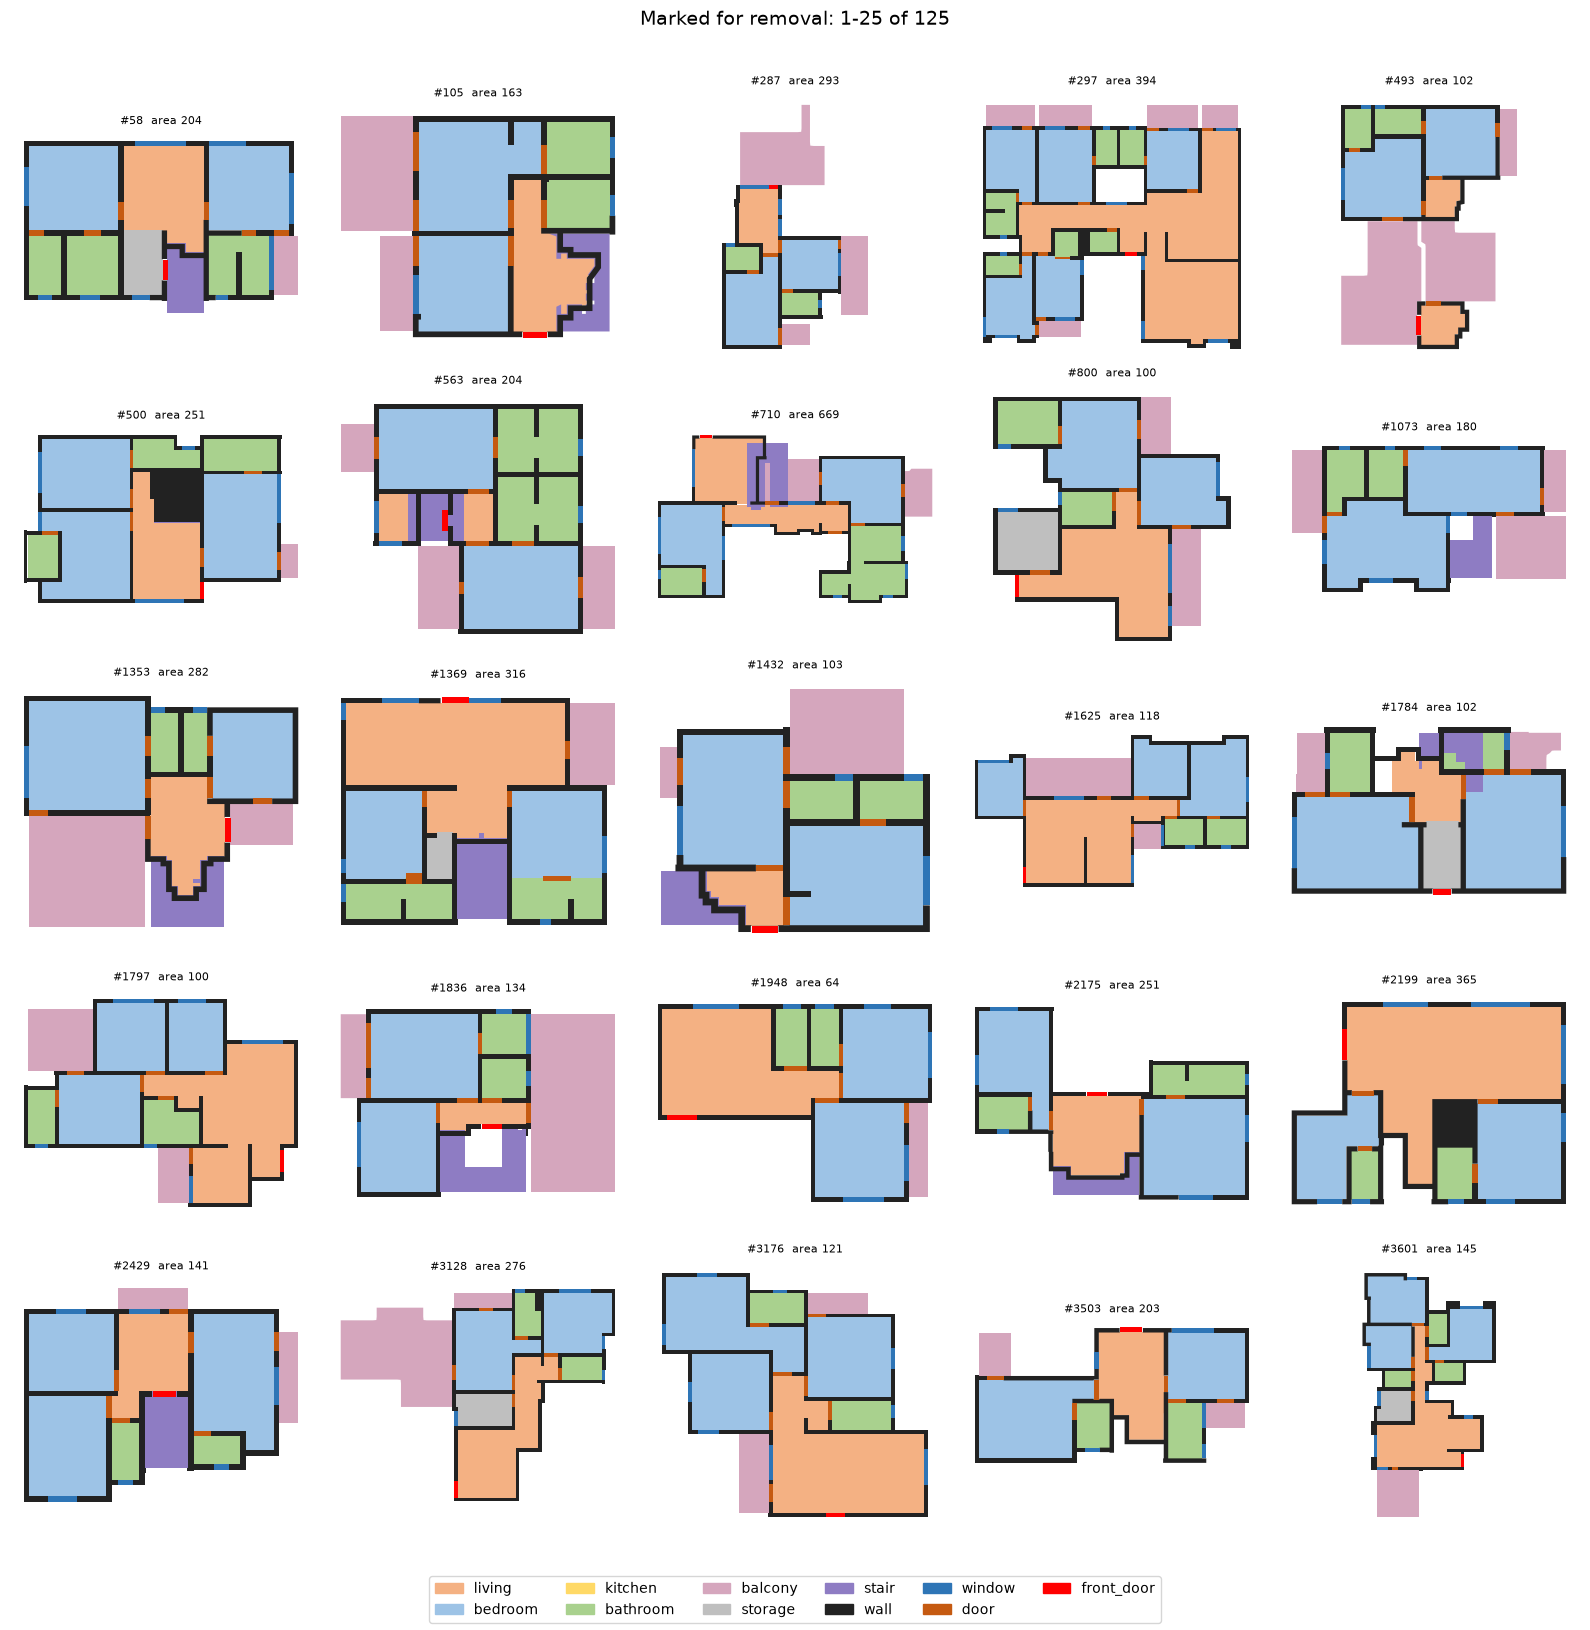

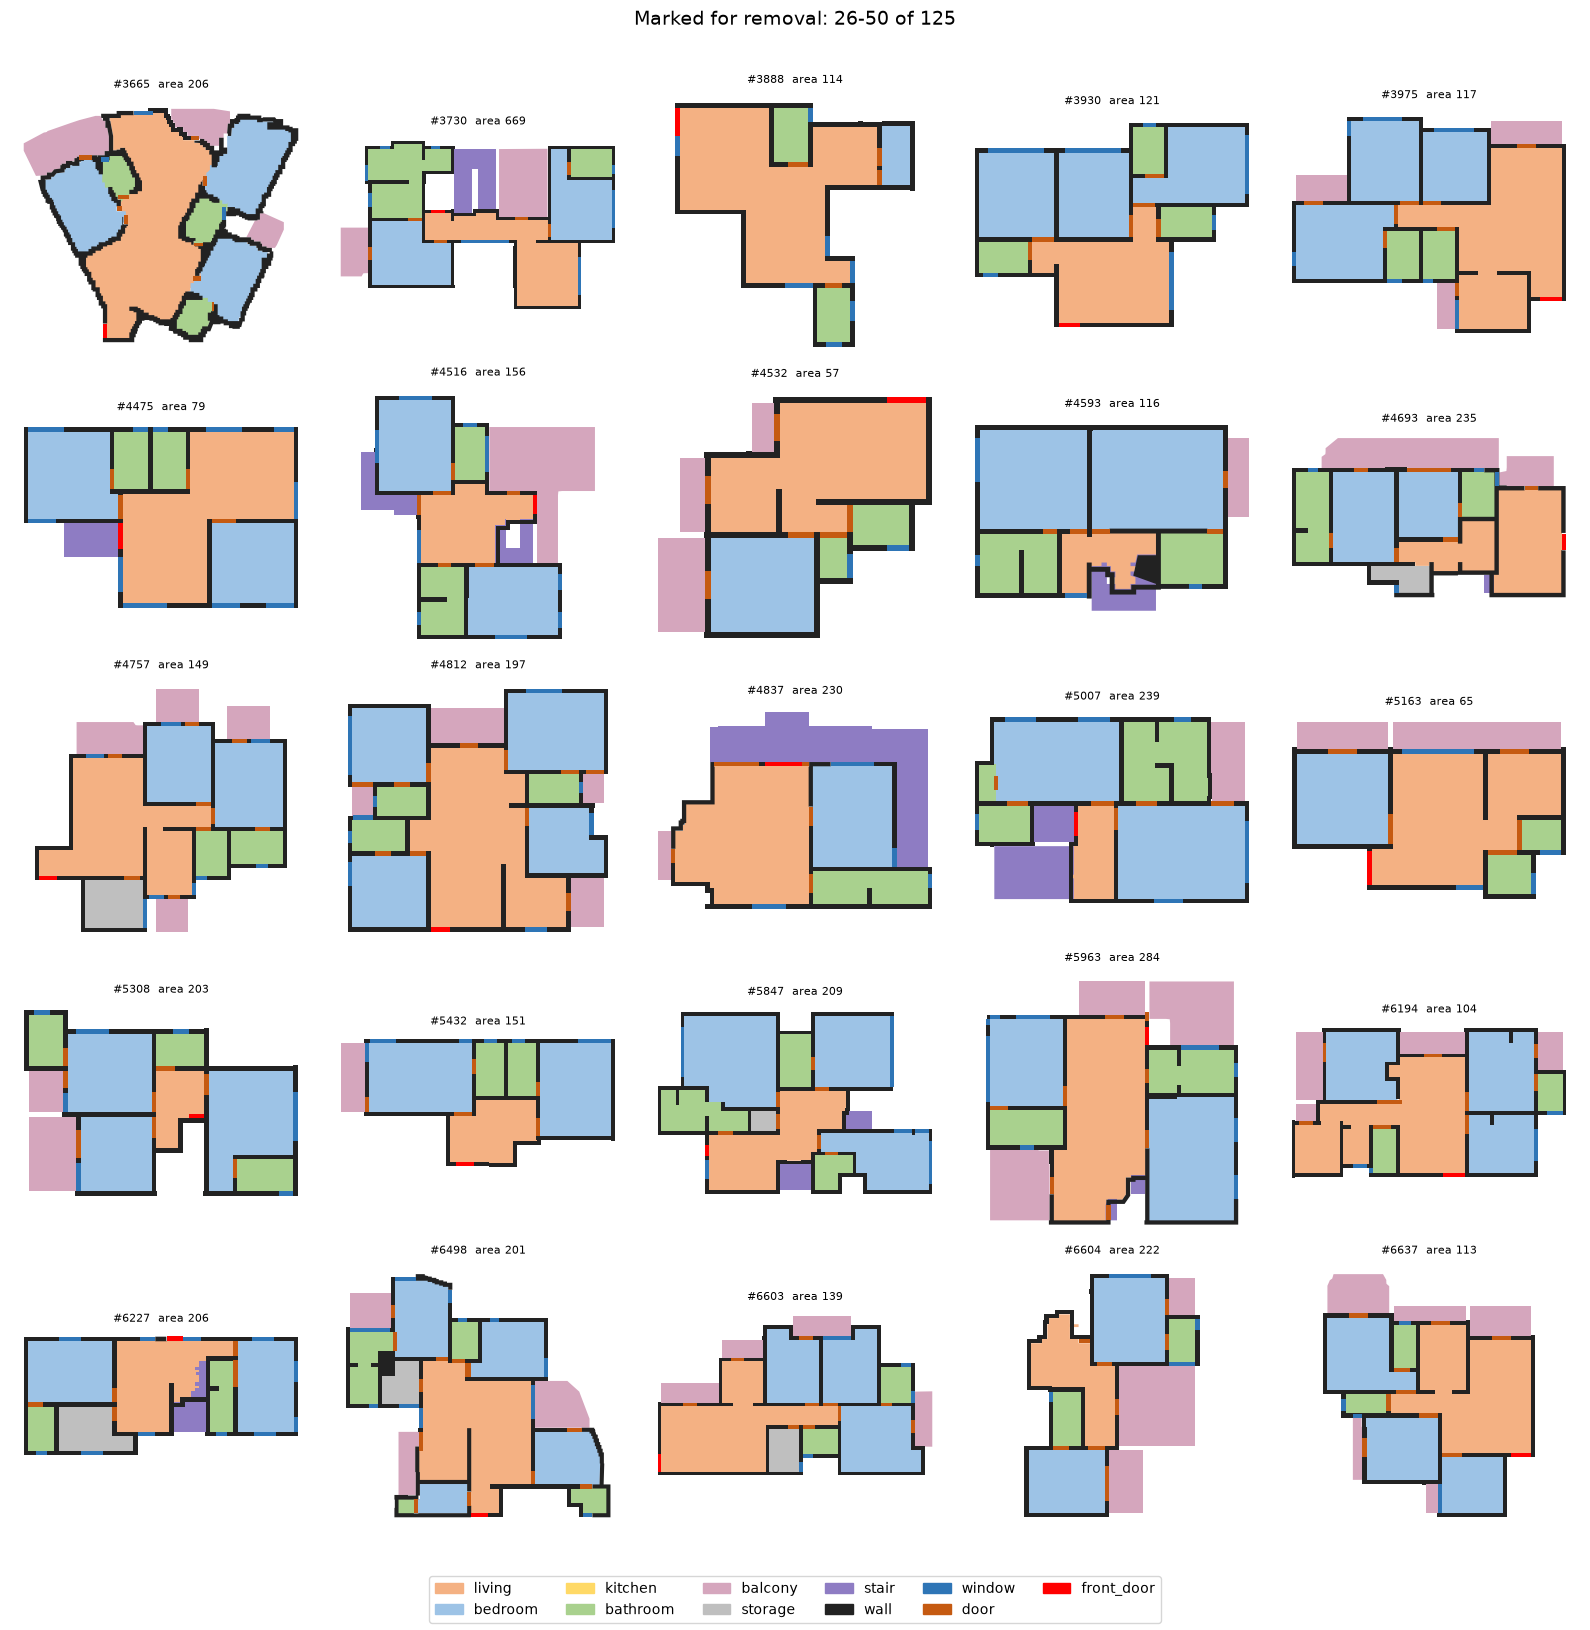

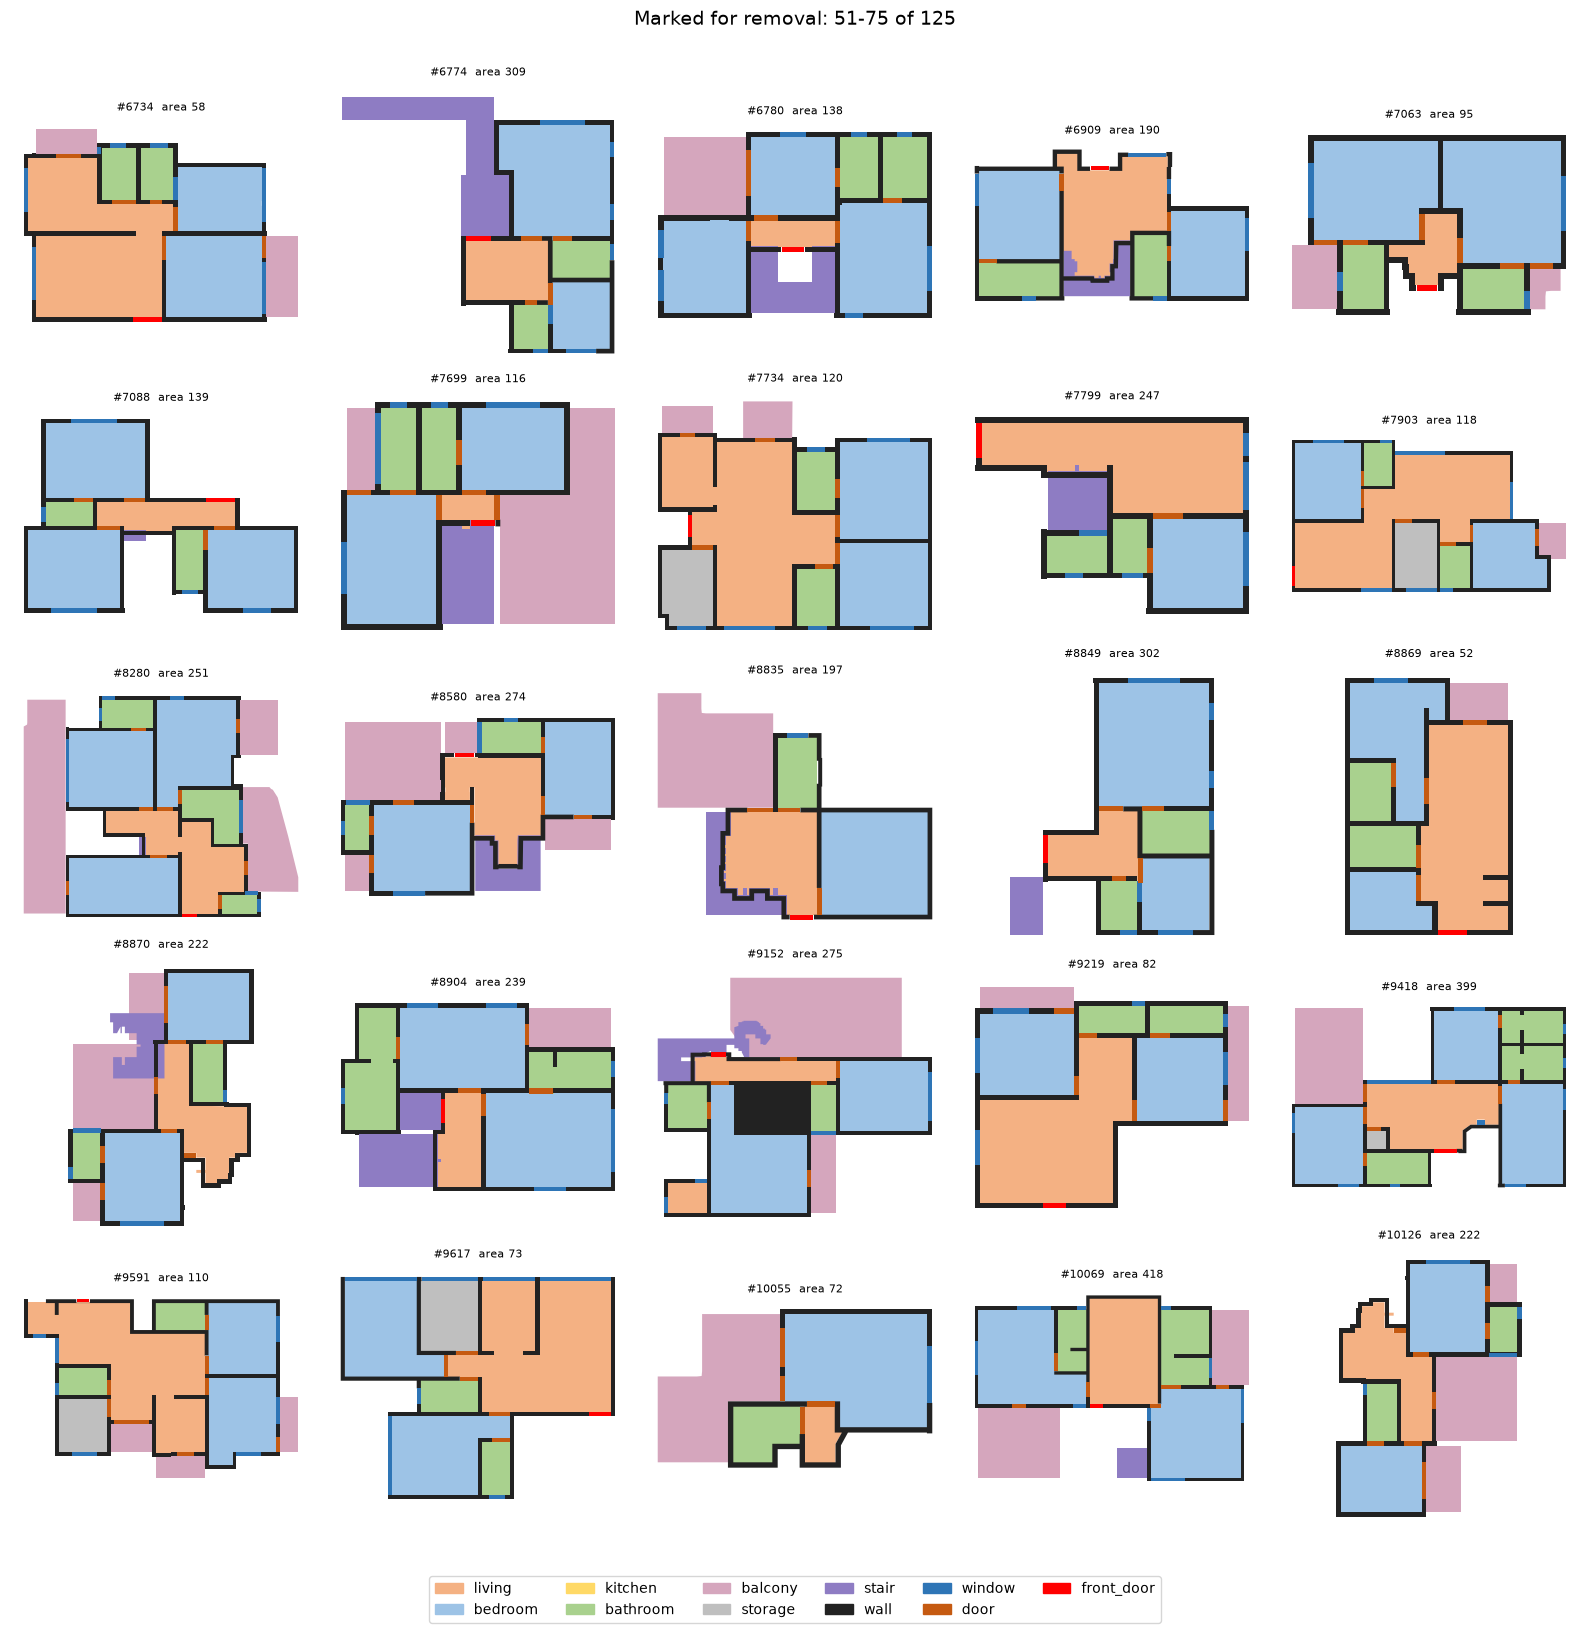

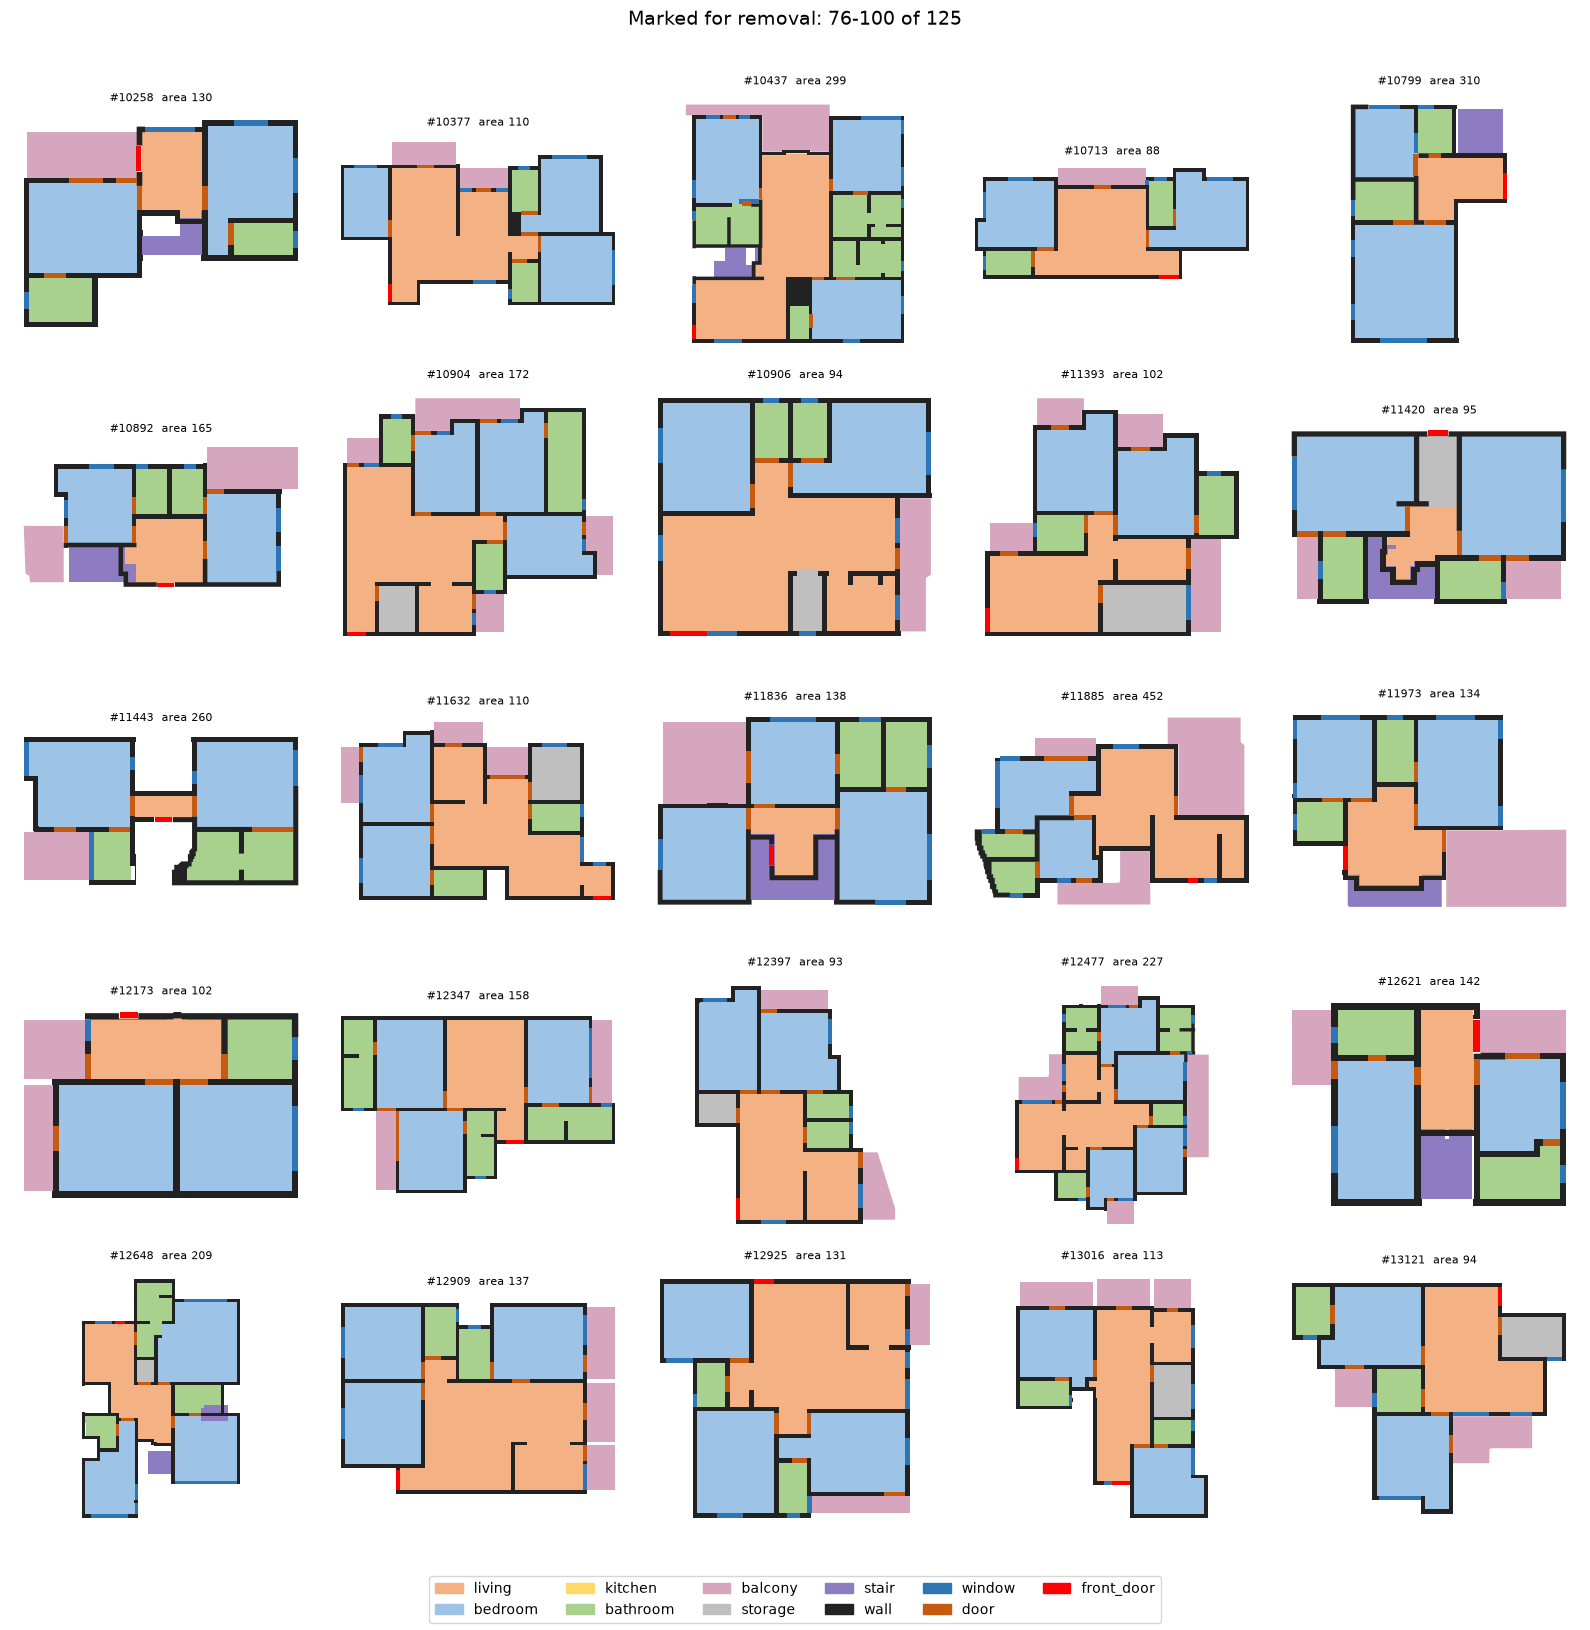

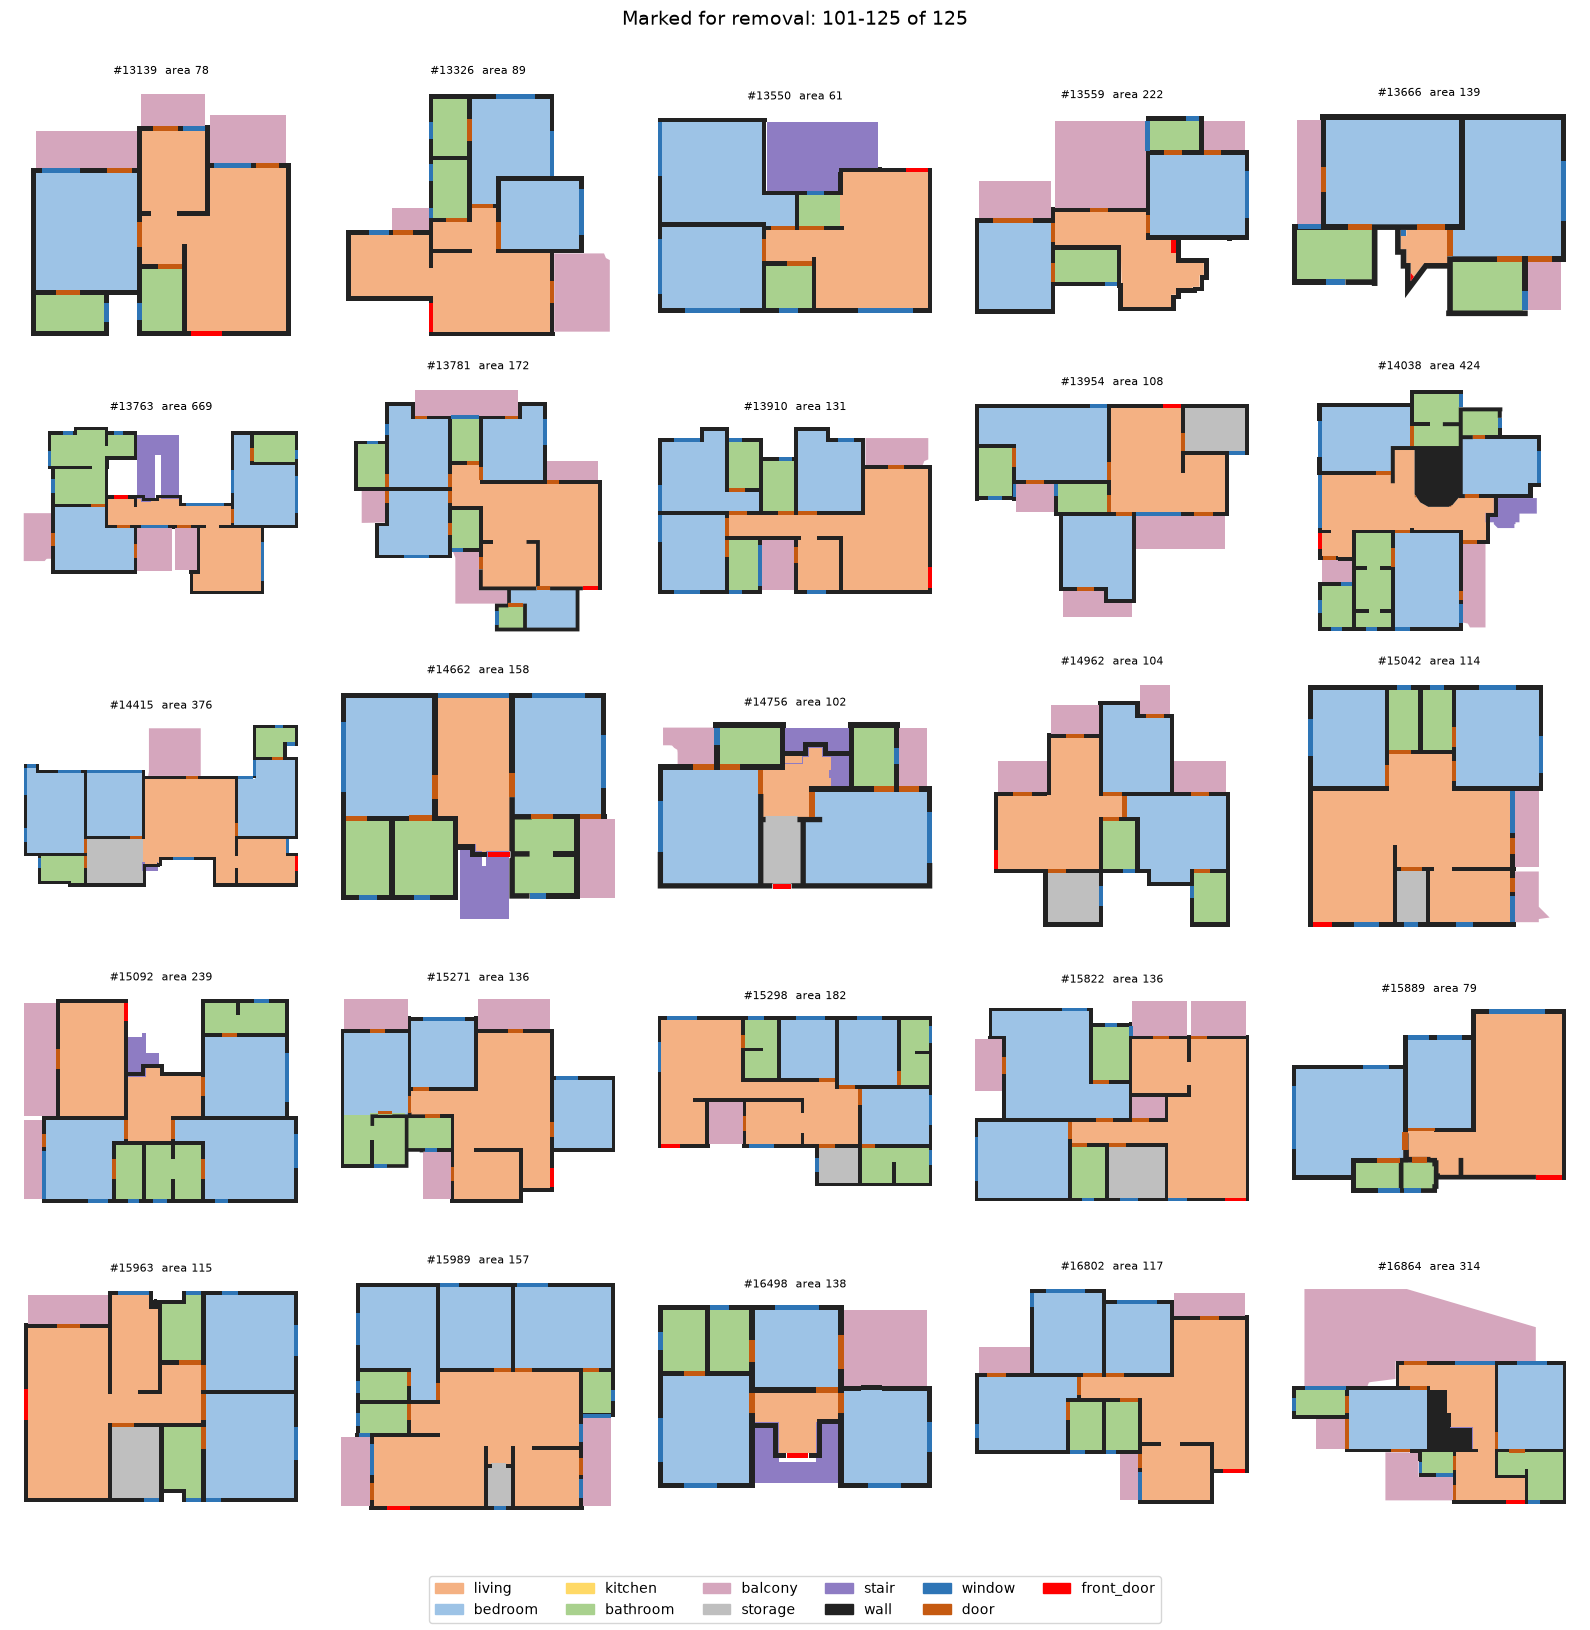

In [10]:
# 1. Create the removal list (only if it doesn't exist yet)
if "to_remove" not in globals():
    to_remove = {}
    for i in suspects["kitchen"]:
        to_remove[i] = "no kitchen (mostly upper floors of houses)"

# 2. Show every marked plan, 25 per grid
marked = sorted(to_remove)
print(f"{len(marked)} plans marked for removal\n")

for start in range(0, len(marked), 25):
    chunk = marked[start:start + 25]
    show_list(chunk, f"Marked for removal: {start + 1}-{start + len(chunk)} of {len(marked)}")

No-kitchen plans:           125
  KEEP - has a stair:       56
  KEEP - studio:            0
  REVIEW - still unclear:   69


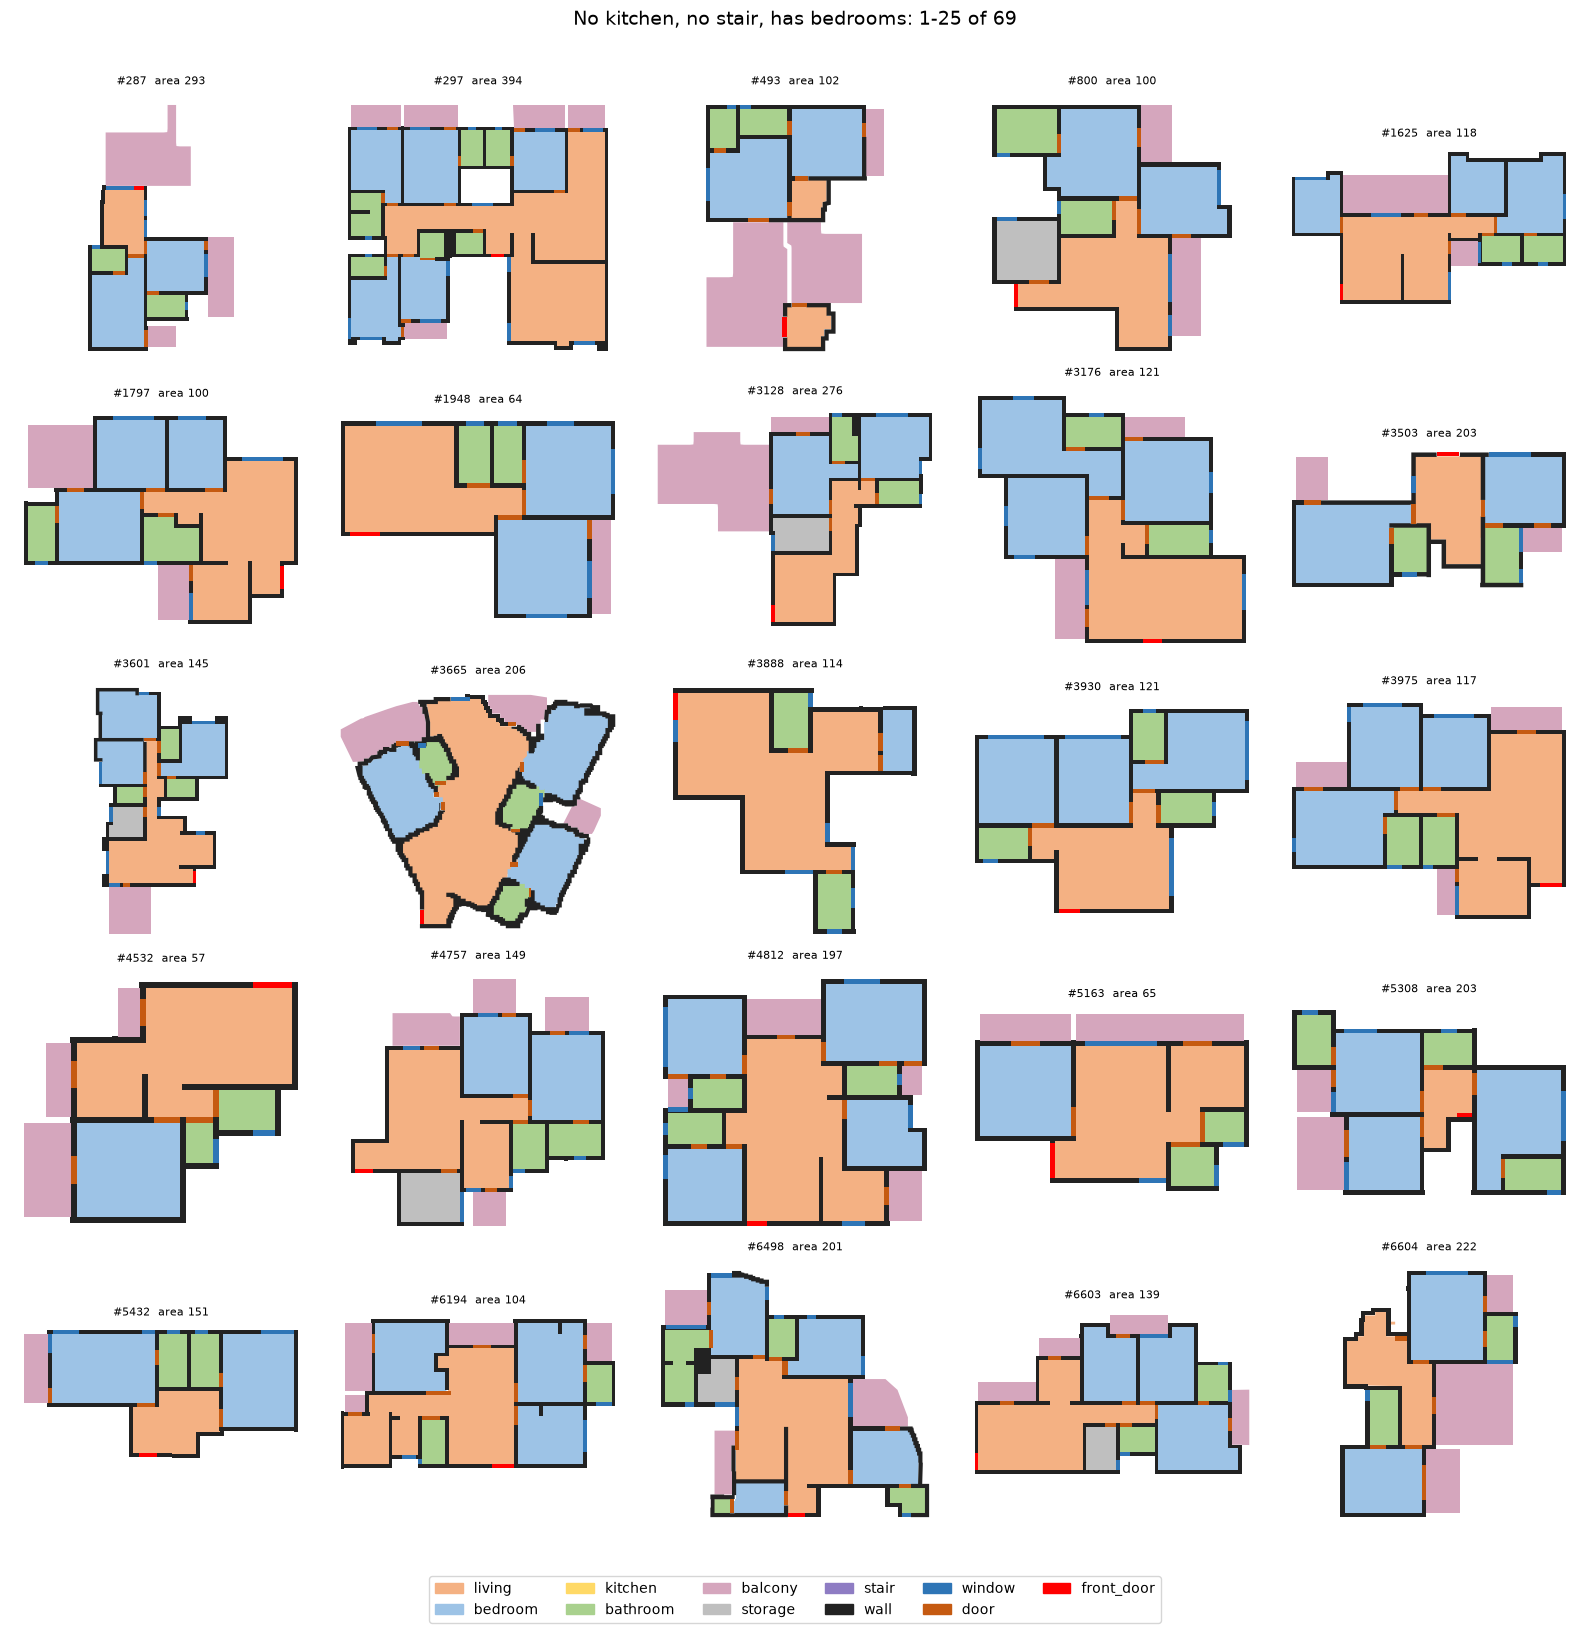

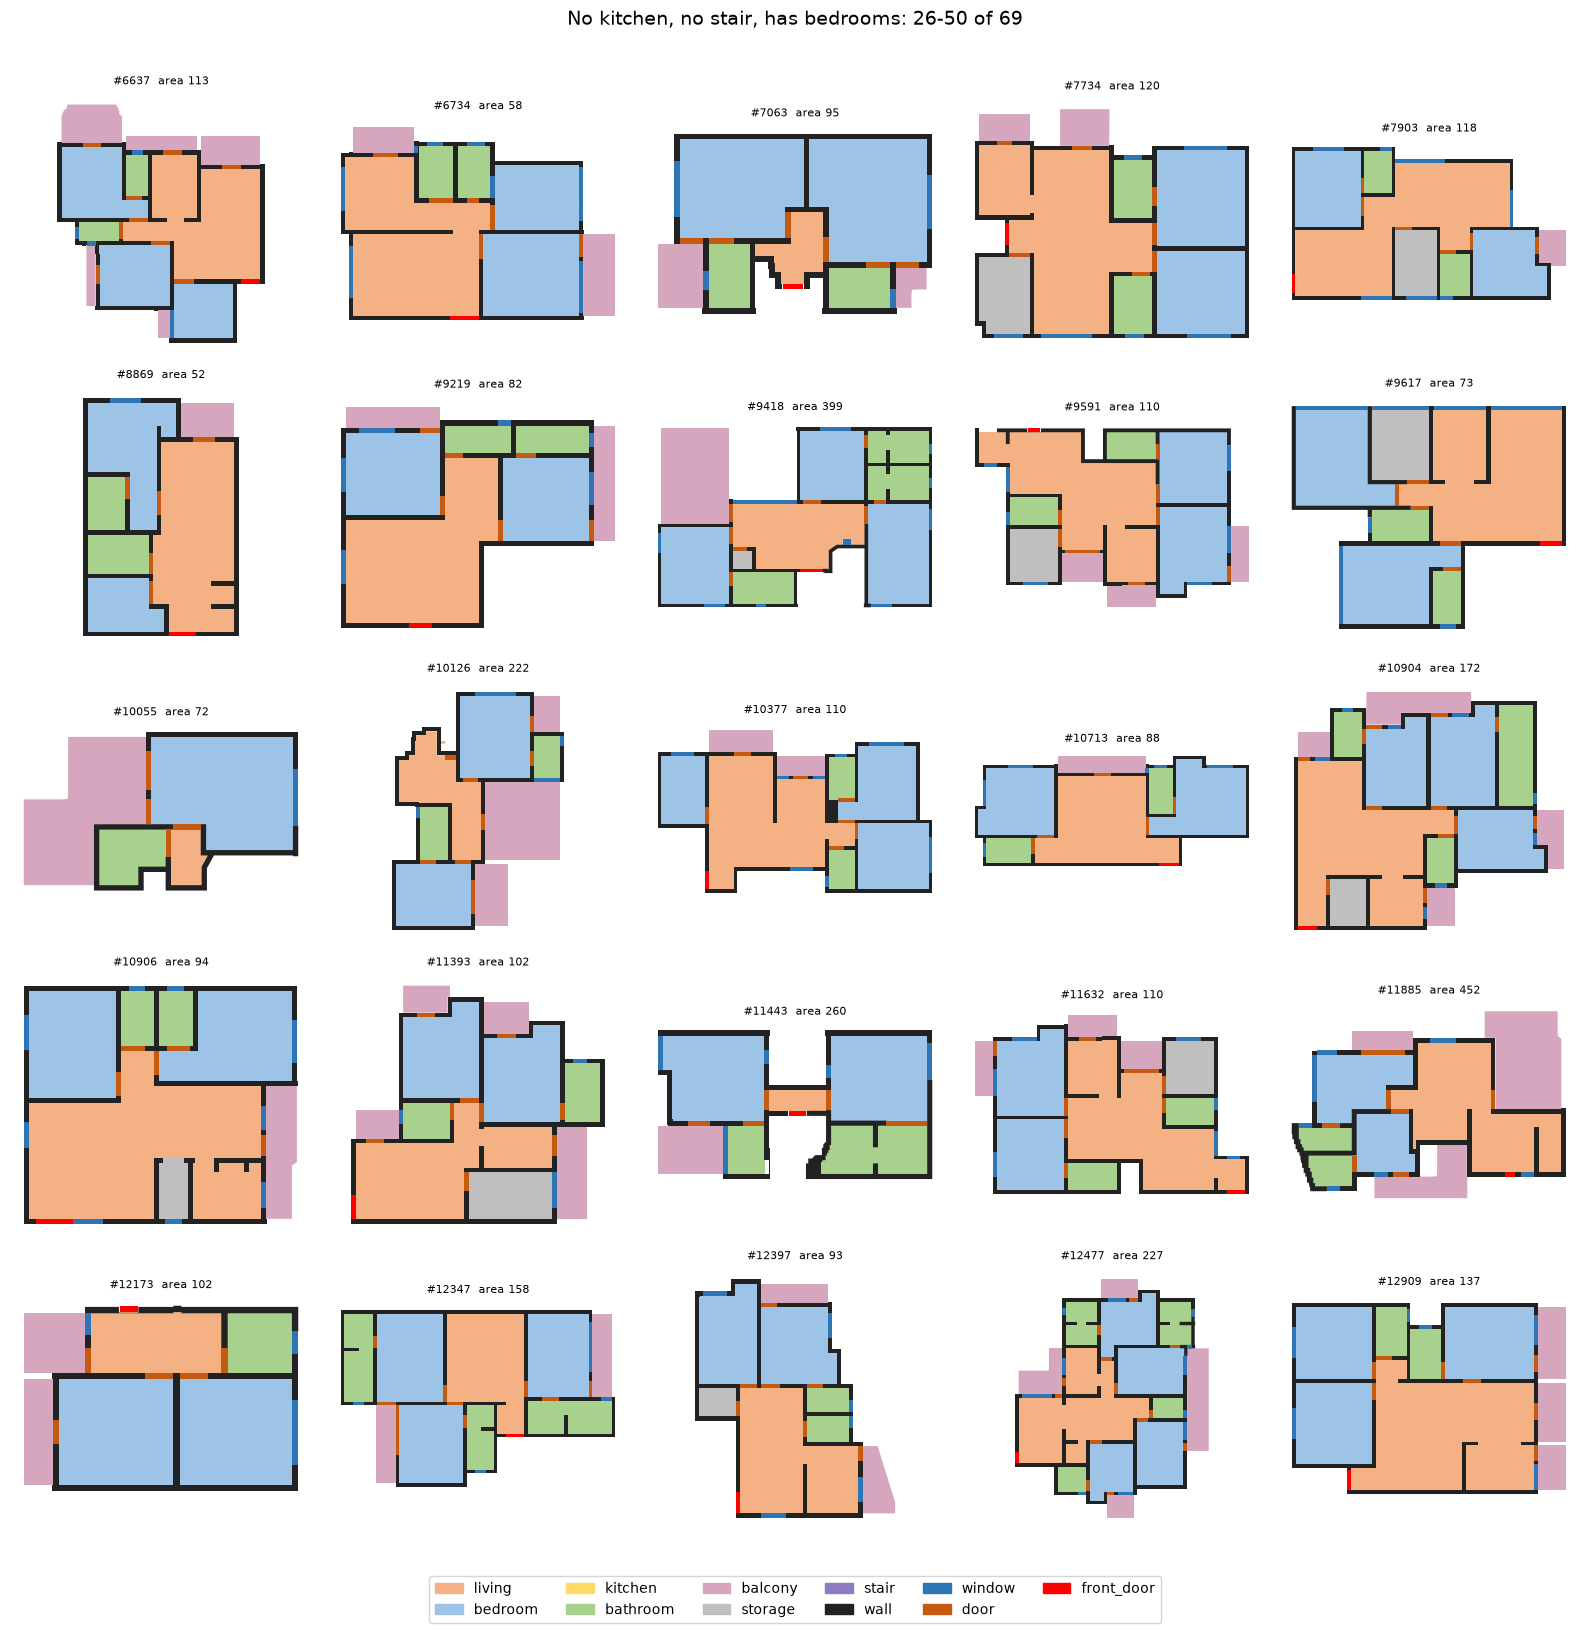

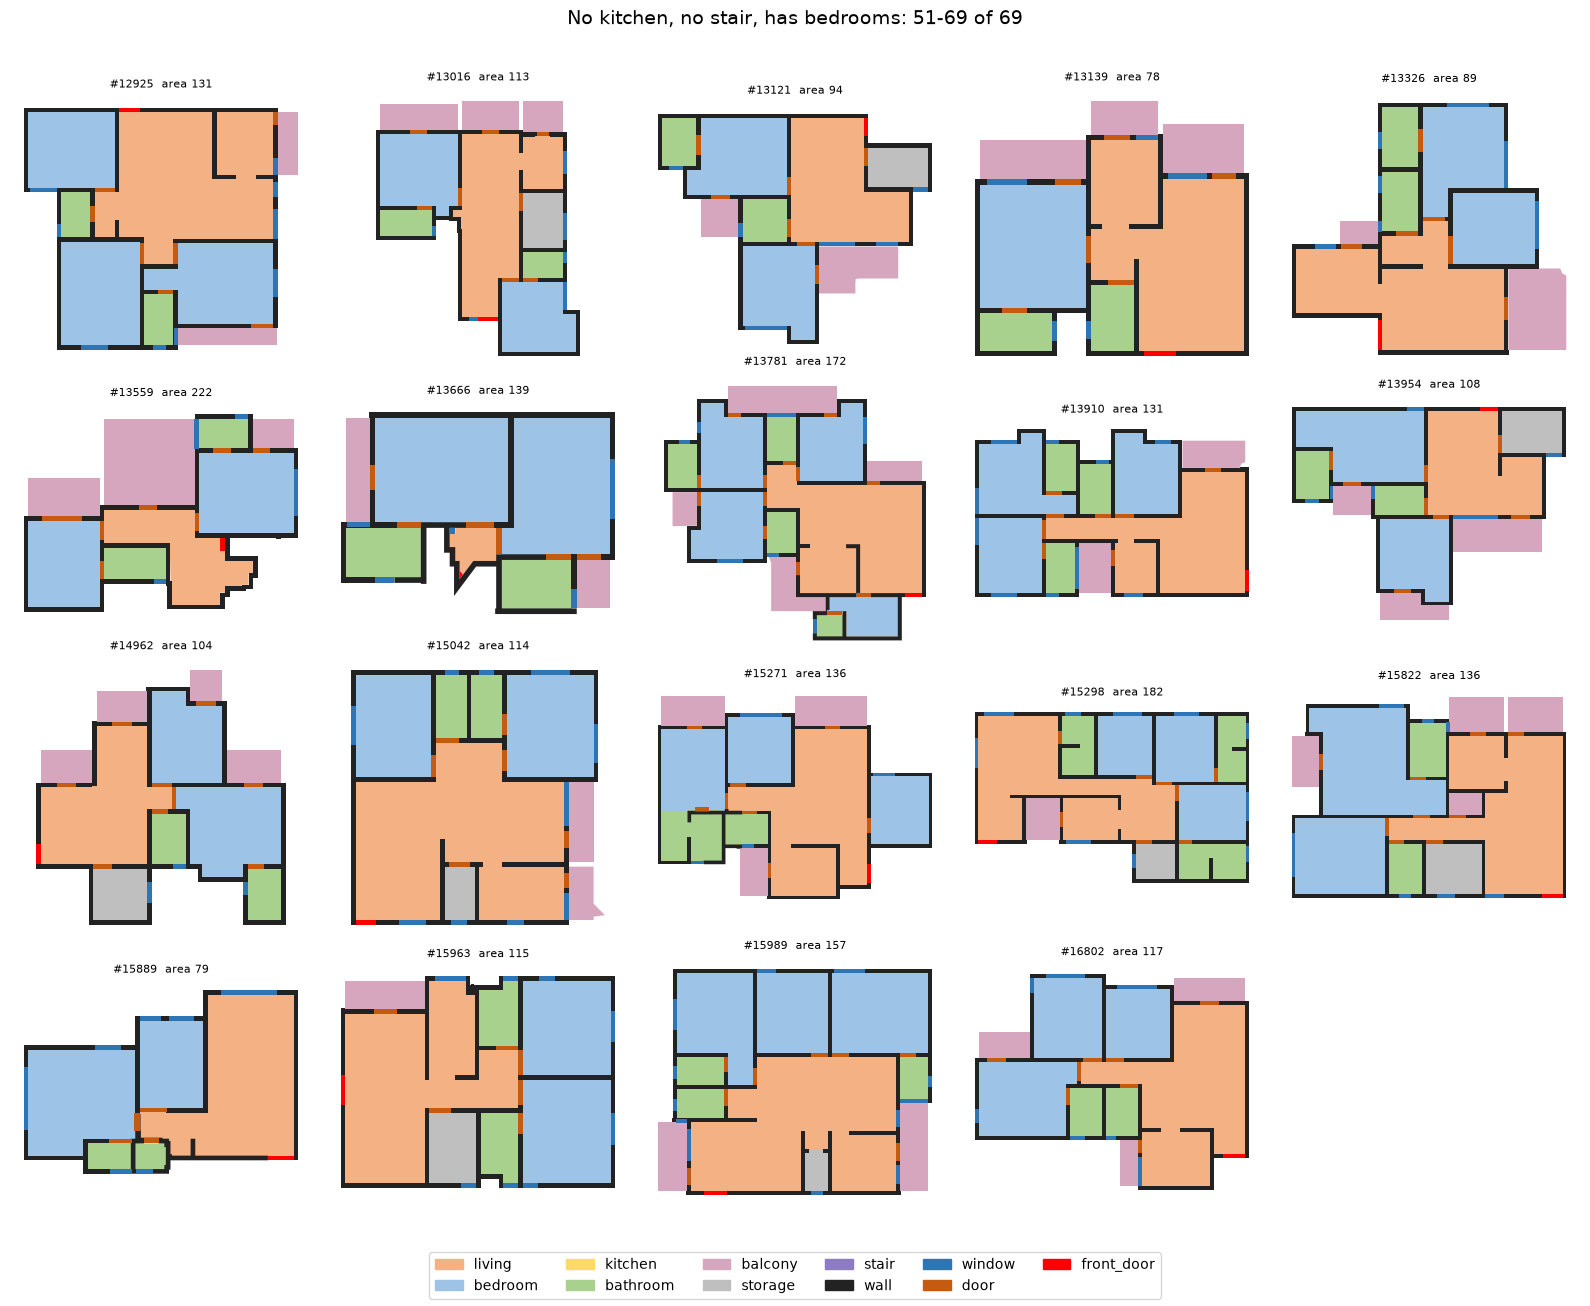

In [11]:
def has(p, key):
    g = p.get(key)
    return g is not None and hasattr(g, "is_empty") and not g.is_empty

def count(p, key):
    g = p.get(key)
    if not has(p, key):
        return 0
    return len(g.geoms) if hasattr(g, "geoms") else 1

keep_stair, keep_studio, review = [], [], []
for i in suspects["kitchen"]:
    p = plans[i]
    if has(p, "stair"):
        keep_stair.append(i)       # multi-level home: kitchen on another floor
    elif count(p, "bedroom") == 0:
        keep_studio.append(i)      # studio
    else:
        review.append(i)           # unclear: check by eye

print("No-kitchen plans:          ", len(suspects["kitchen"]))
print("  KEEP - has a stair:      ", len(keep_stair))
print("  KEEP - studio:           ", len(keep_studio))
print("  REVIEW - still unclear:  ", len(review))

# Start the removal list EMPTY. Nothing is marked until you decide.
to_remove = {}

for start in range(0, len(review), 25):
    chunk = review[start:start + 25]
    show_list(chunk, f"No kitchen, no stair, has bedrooms: {start + 1}-{start + len(chunk)} of {len(review)}")

In [12]:
# Keep all no-kitchen plans, but remember which ones they are
kitchen_in_living = set(suspects["kitchen"])
print("Plans tagged 'kitchen labelled as living':", len(kitchen_in_living))

to_remove = {}   # nothing removed for the kitchen issue
print("Plans marked for removal:", len(to_remove))

Plans tagged 'kitchen labelled as living': 125
Plans marked for removal: 0


### Finding 1: Plans without a kitchen (125 plans, 0.7%)
- Visual check: most DO have a kitchen, but it is **labelled as part of the living room** (kitchen alcove inside the living polygon).
- Some are one floor of a multi-level home (45% have a staircase vs 4% overall).
- **Decision:** kept, but tagged as `kitchen_in_living` so they can be filtered later.

No front door: 5 plans
No window:     51 plans


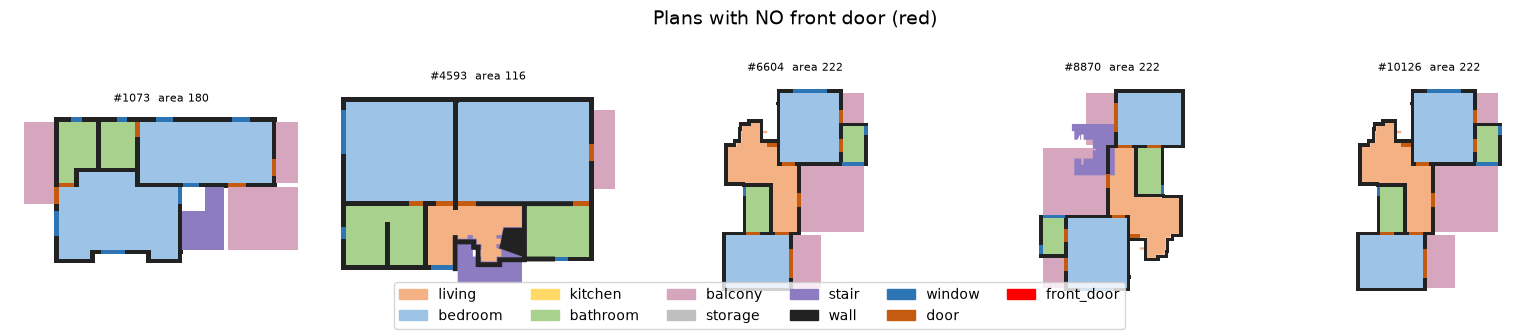

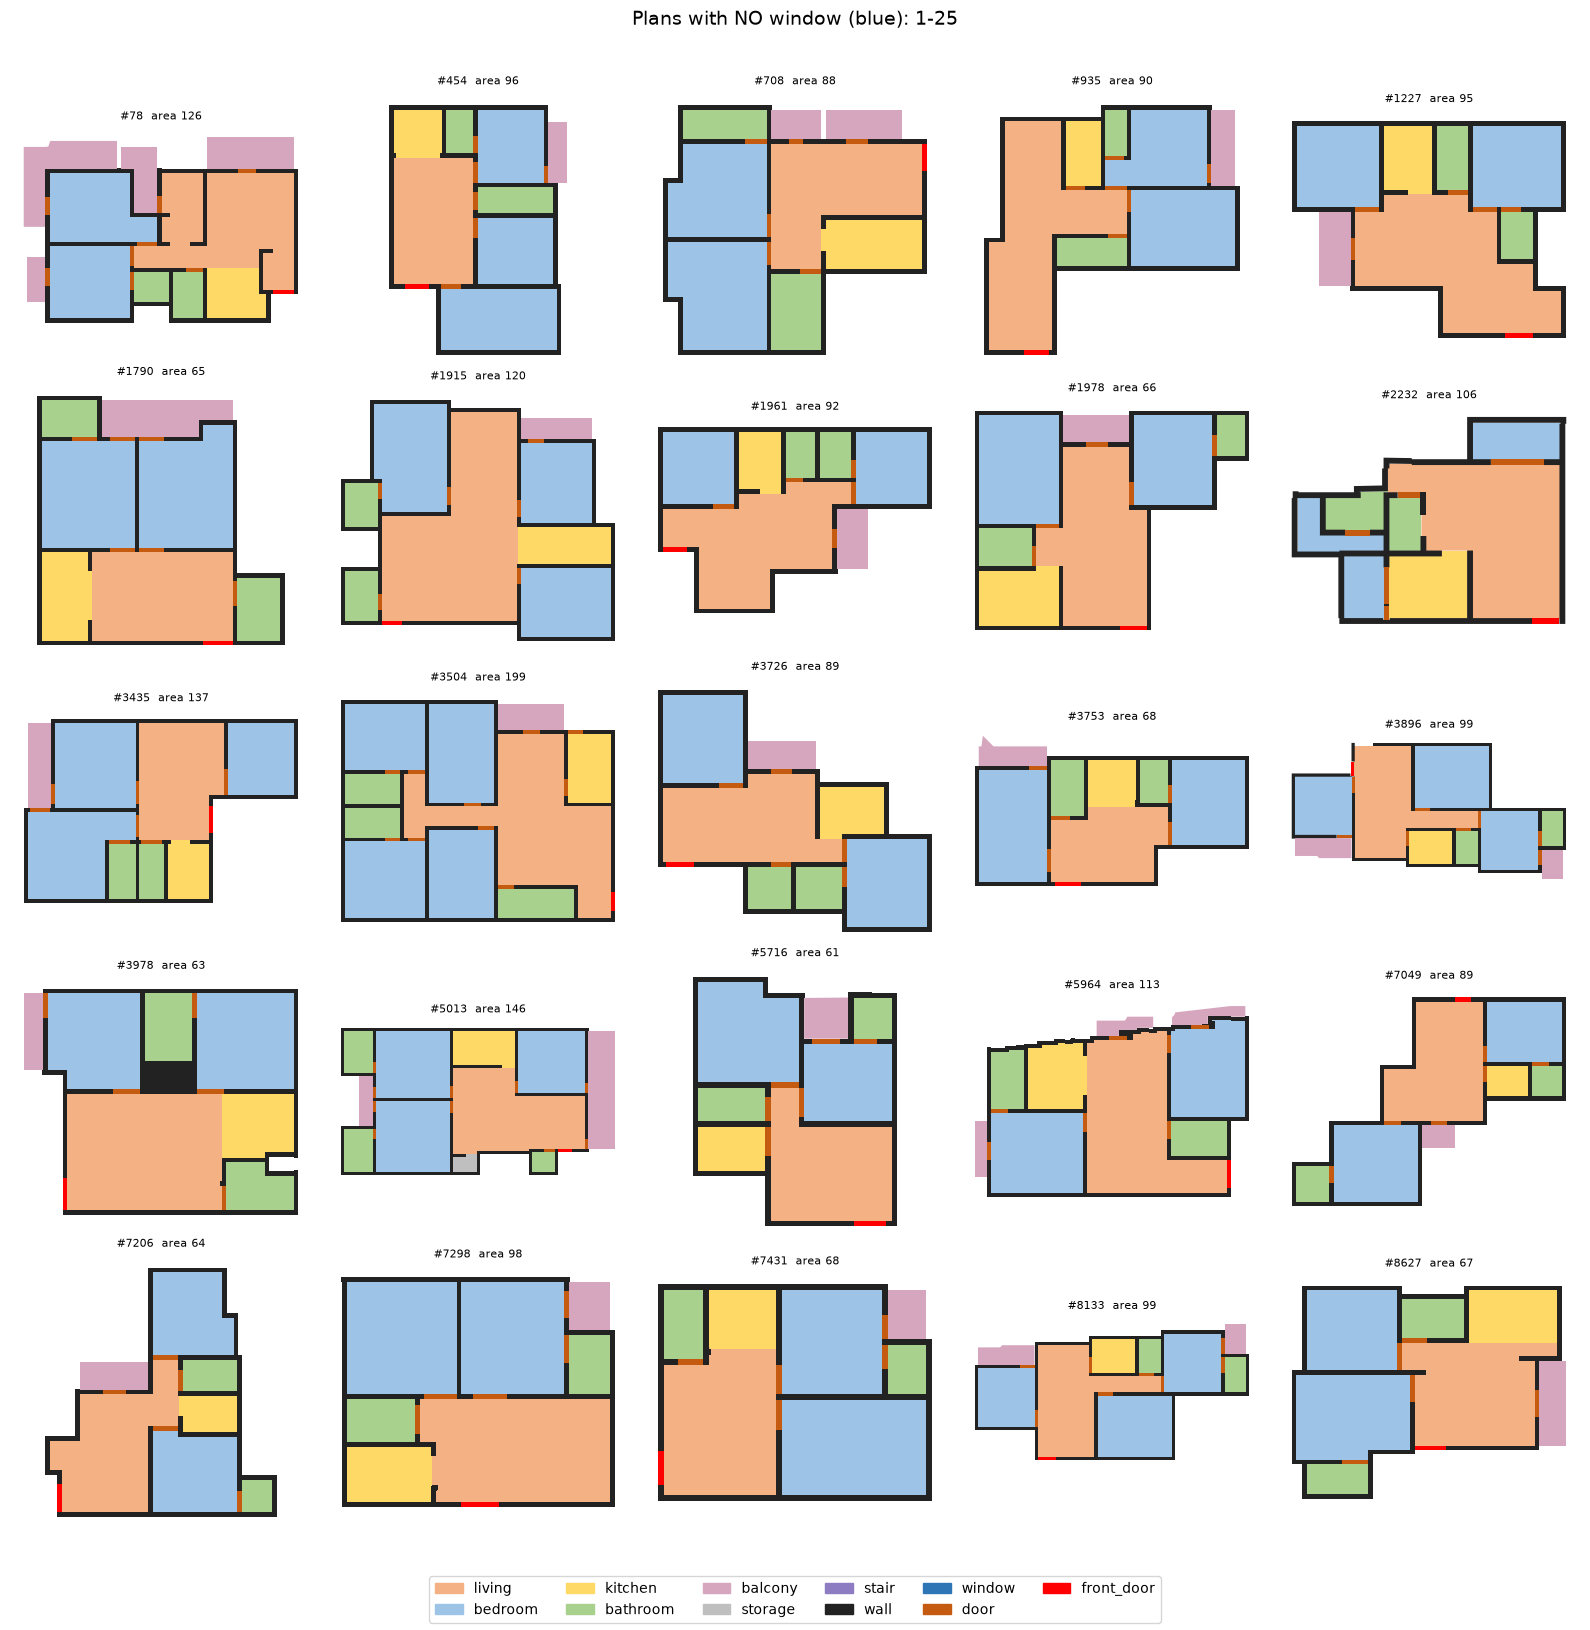

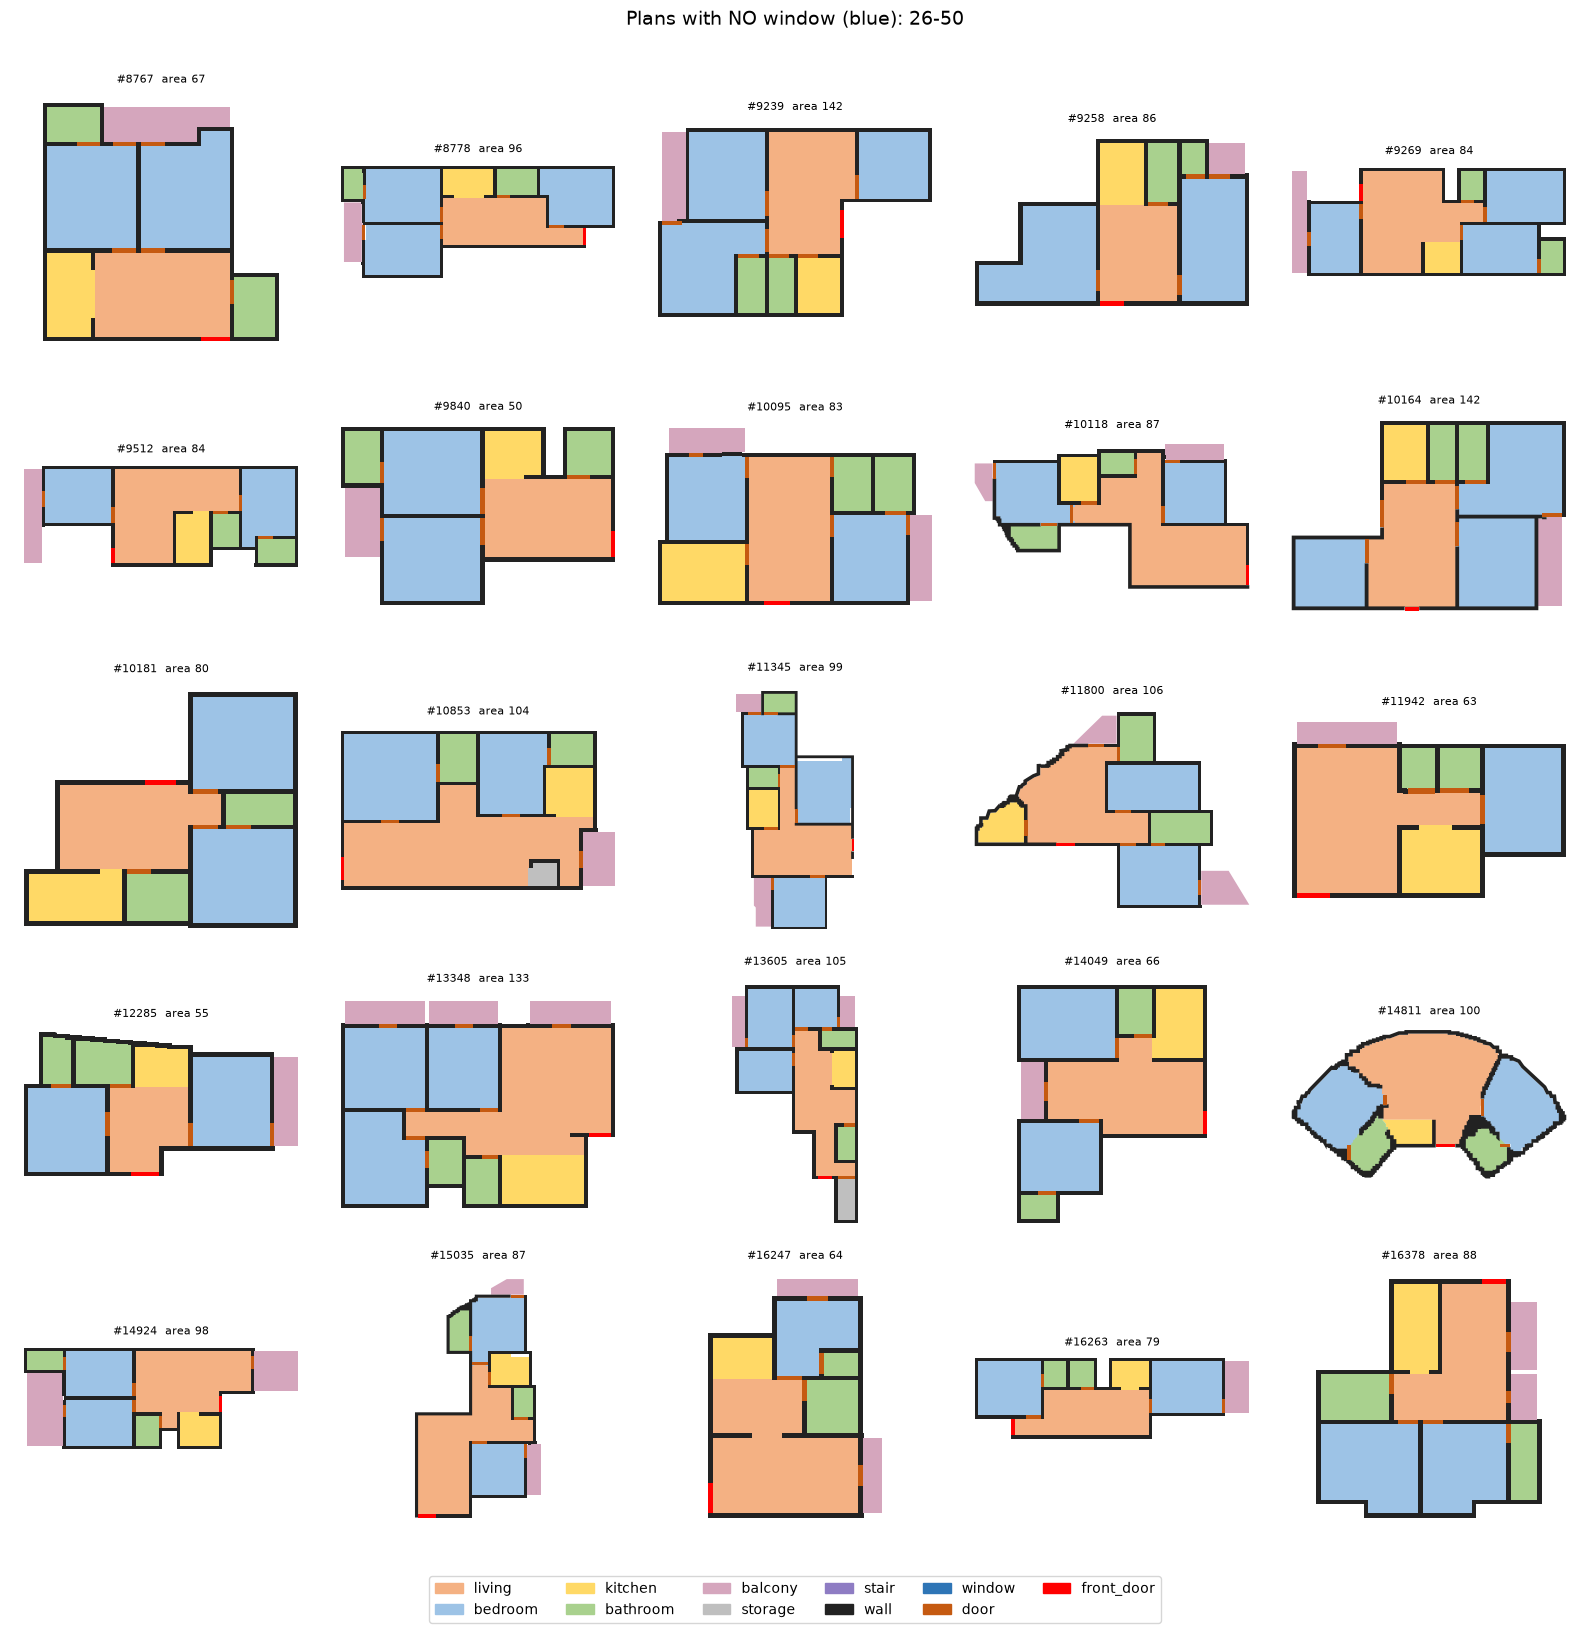

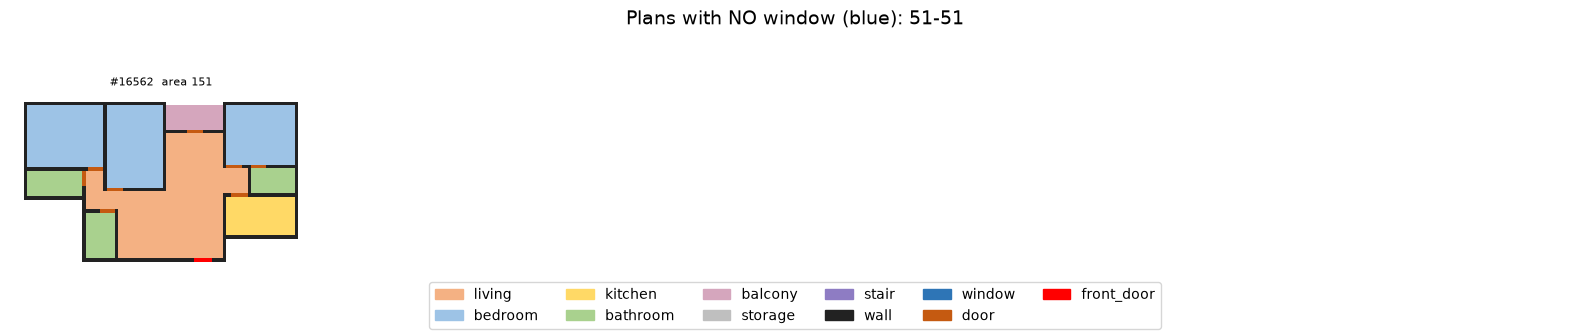

In [13]:
print("No front door:", len(suspects["front_door"]), "plans")
print("No window:    ", len(suspects["window"]), "plans")

show_list(suspects["front_door"], "Plans with NO front door (red)")

for start in range(0, len(suspects["window"]), 25):
    chunk = suspects["window"][start:start + 25]
    show_list(chunk, f"Plans with NO window (blue): {start + 1}-{start + len(chunk)}")

In [14]:
# Separate tags: these plans are KEPT, just labelled
no_window     = set(suspects["window"])
no_front_door = set(suspects["front_door"])

print("Tagged 'no window':        ", len(no_window))
print("Tagged 'no front door':    ", len(no_front_door))
print("Tagged 'kitchen_in_living':", len(kitchen_in_living))

# Plans that have more than one tag
print("\nNo window AND no front door:", sorted(no_window & no_front_door))
print("No window AND no kitchen:   ", len(no_window & kitchen_in_living))

# Add the tags as columns to the table, so you can filter by them
df["kitchen_in_living"] = df["idx"].isin(kitchen_in_living)
df["no_window"]         = df["idx"].isin(no_window)
df["no_front_door"]     = df["idx"].isin(no_front_door)

print("\nPlans with at least one tag:",
      (df.kitchen_in_living | df.no_window | df.no_front_door).sum())

Tagged 'no window':         51
Tagged 'no front door':     5
Tagged 'kitchen_in_living': 125

No window AND no front door: []
No window AND no kitchen:    0

Plans with at least one tag: 176


### Finding 2: Plans without windows or a front door
- `no_window`: plans with no window shapes.
- `no_front_door`: plans with no front door shape.
- **Decision:** kept, each tagged separately so they can be filtered later.

In [15]:
print("Total plans:                  ", len(df))
print("Duplicate ids:                ", df["id"].duplicated().sum())
print("Plans with broken shapes:     ", (df.broken_shapes > 0).sum())
print("Plans with empty shapes:      ", (df.empty_shapes > 0).sum())
print("Plans with no outline:        ", df.no_outline.sum())
print("Plans with no bedroom:        ", len(suspects["bedroom"]))
print("net_area = 0:                 ", (df.net_area == 0).sum())
print("net_area bigger than area:    ", (df.net_area > df.area).sum())
print()
print(df[["area", "wall_depth", "n_rooms"]].describe().round(1))

Total plans:                   17000
Duplicate ids:                 0
Plans with broken shapes:      862
Plans with empty shapes:       17000
Plans with no outline:         0
Plans with no bedroom:         3
net_area = 0:                  5458
net_area bigger than area:     1796

          area  wall_depth  n_rooms
count  17000.0     17000.0  17000.0
mean     120.7         4.2      9.2
std       55.2         0.7      2.1
min        0.1         2.2      4.0
25%       87.1         3.7      8.0
50%      109.6         4.1      9.0
75%      140.8         4.6     10.0
max      712.9         7.2     23.0


Plans with broken shapes: 862
Which parts are broken: [('window', 399), ('door', 364), ('land', 111), ('bedroom', 7), ('bathroom', 5)]


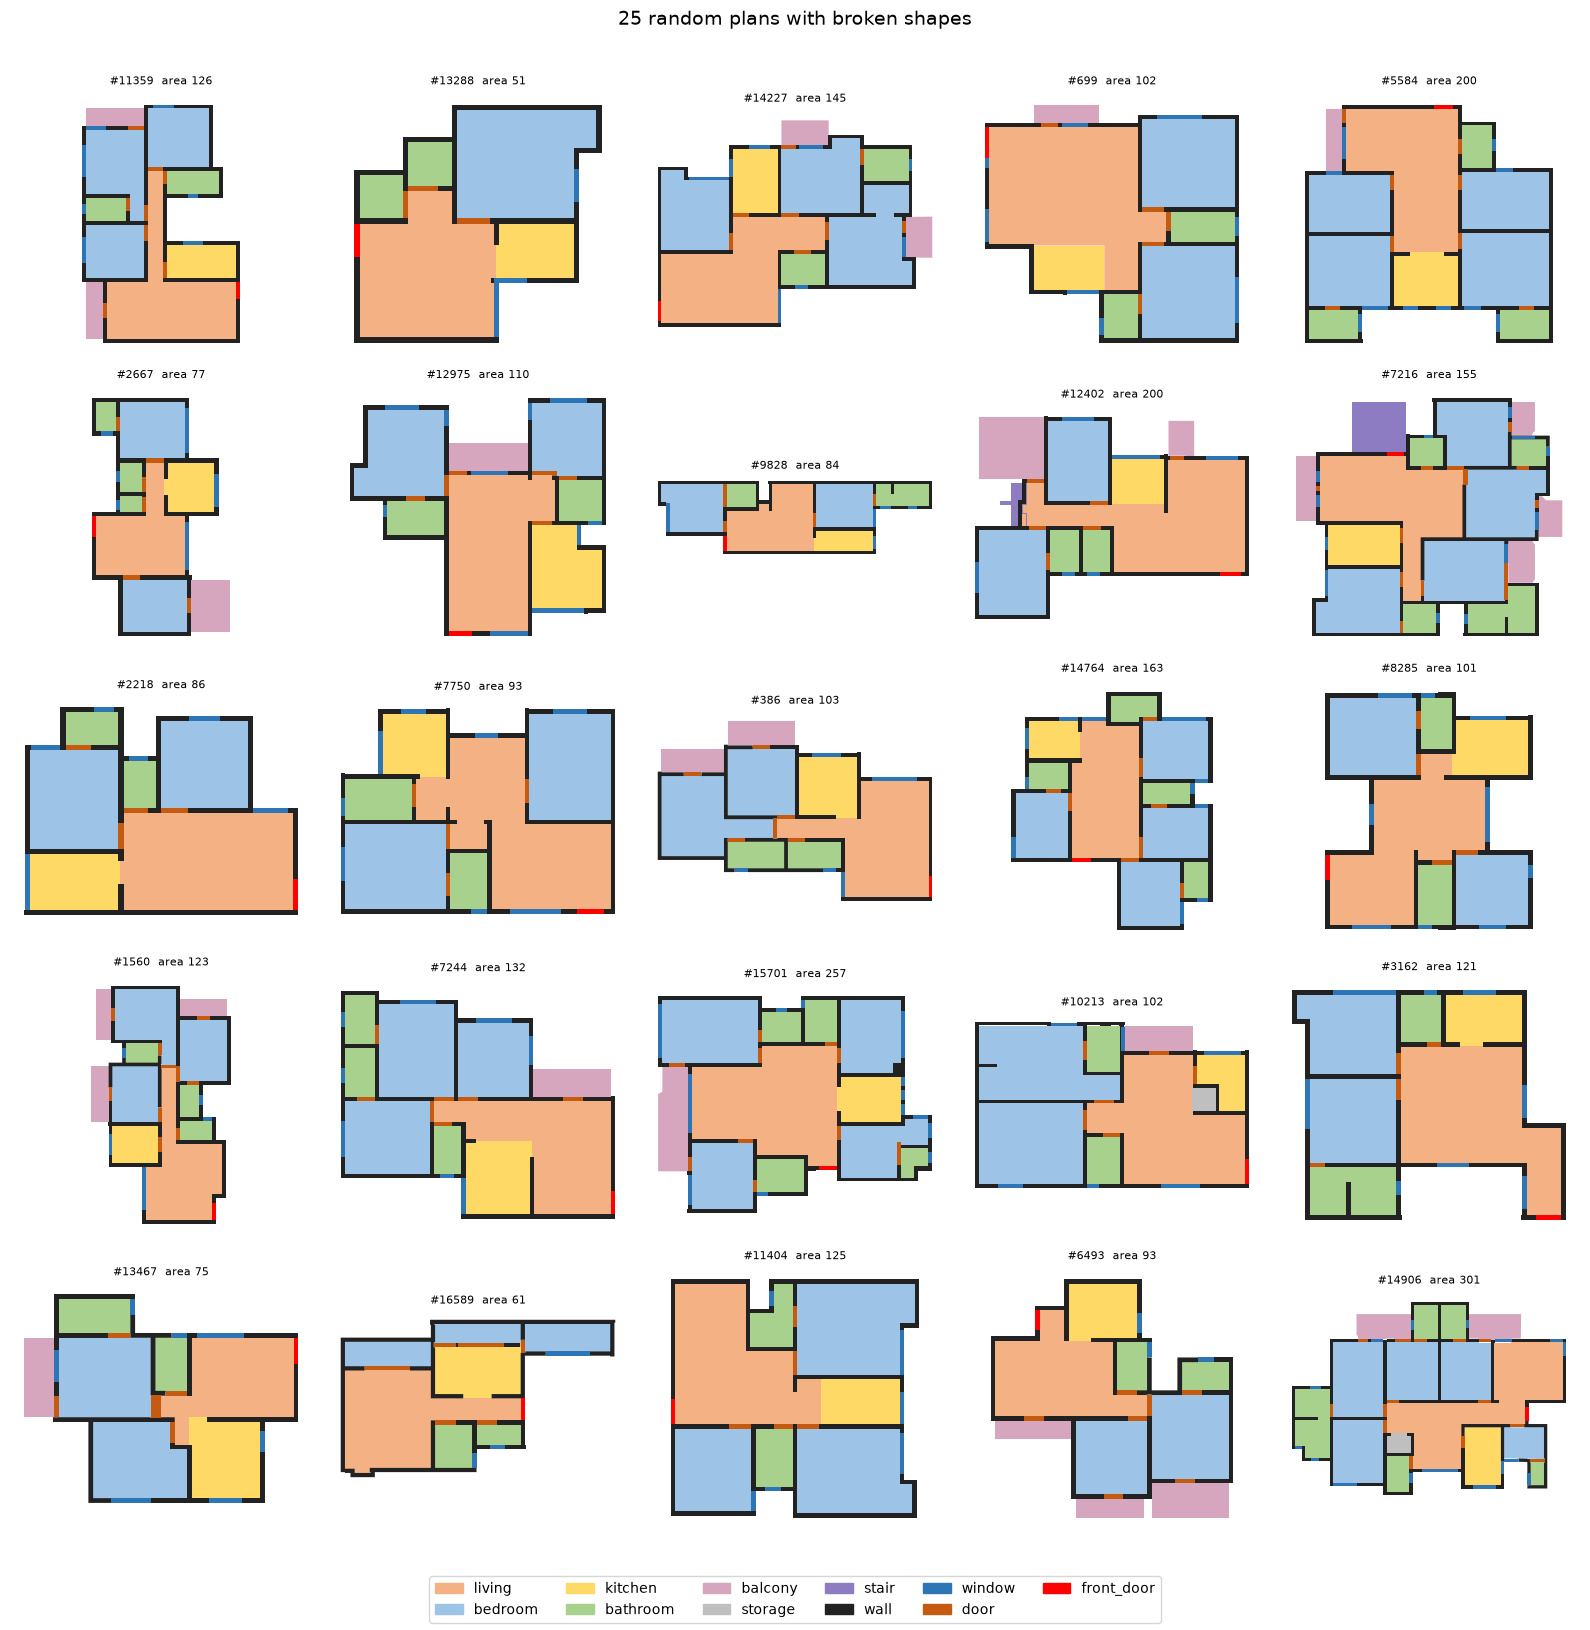

In [16]:
from collections import Counter

broken_idx, broken_parts = [], Counter()
for i, p in enumerate(plans):
    bad = [k for k, g in p.items()
           if hasattr(g, "is_valid") and not g.is_empty and not g.is_valid]
    if bad:
        broken_idx.append(i)
        broken_parts.update(bad)

print("Plans with broken shapes:", len(broken_idx))
print("Which parts are broken:", broken_parts.most_common())

show_list(random.sample(broken_idx, 25), "25 random plans with broken shapes")

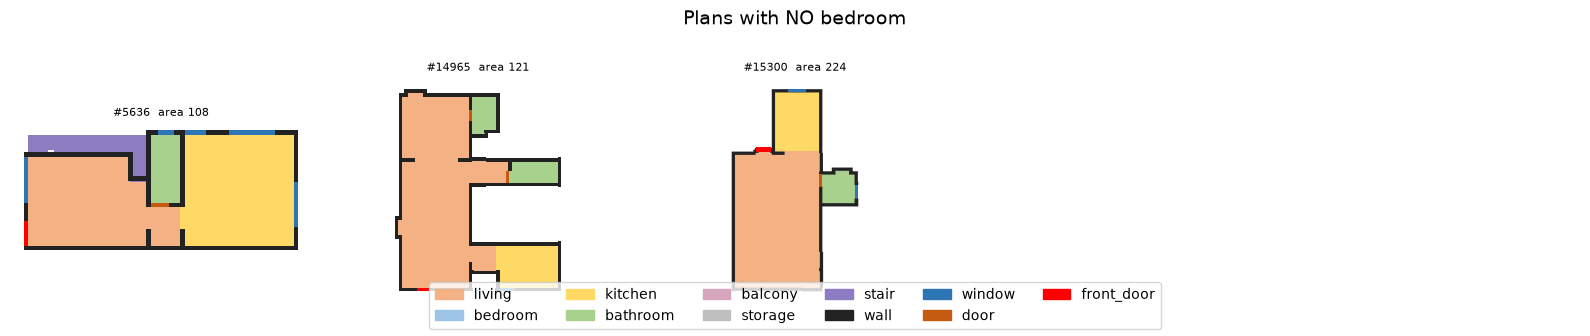

In [17]:
show_list(suspects["bedroom"], "Plans with NO bedroom")

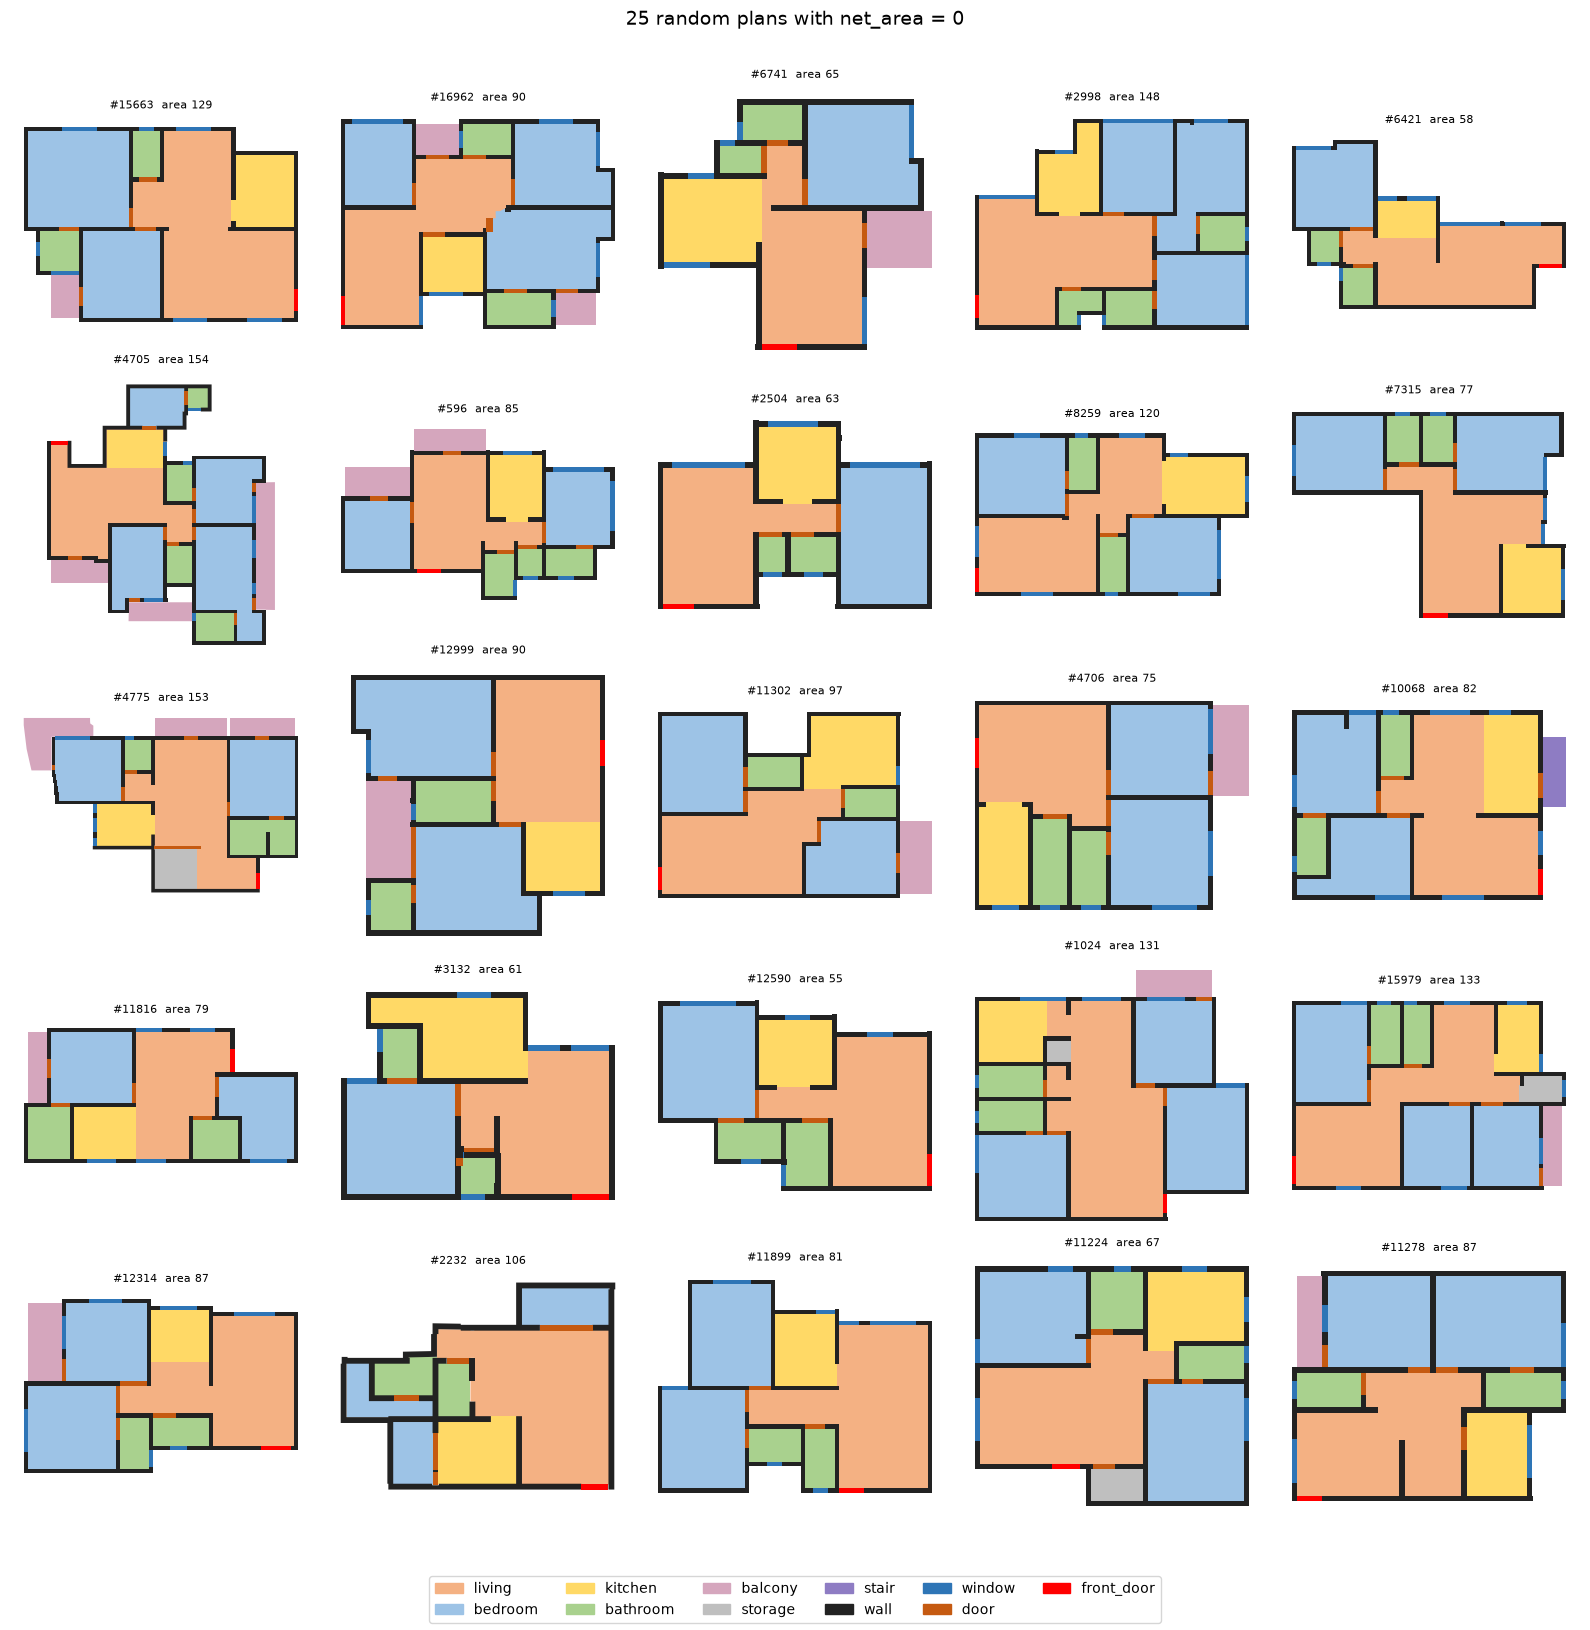

In [18]:
zero_net = df.loc[df.net_area == 0, "idx"].tolist()
show_list(random.sample(zero_net, 25), "25 random plans with net_area = 0")

  idx      area  n_rooms
 5227  0.092903        9
 5969  0.185806       10
 8491  0.278709       10
13524  0.371612        9
 7638  0.464515        9
 7818  0.464515        9
10333 14.841113        7
 6674 20.903175        7
10532 23.445381        6
  833 24.396267        7
16648 30.438829        6
 3182 30.641628        8
11357 32.051535        6
 5017 32.516050        7
 7367 32.516050        6
12221 32.516050        6
13573 32.533769        6
13017 32.894087        6
 6693 32.988154        9
 8715 33.168389        6
12751 33.168389        6
15863 34.002498        7
16979 34.046969        9
 9204 34.188304        6
16493 36.080951        6


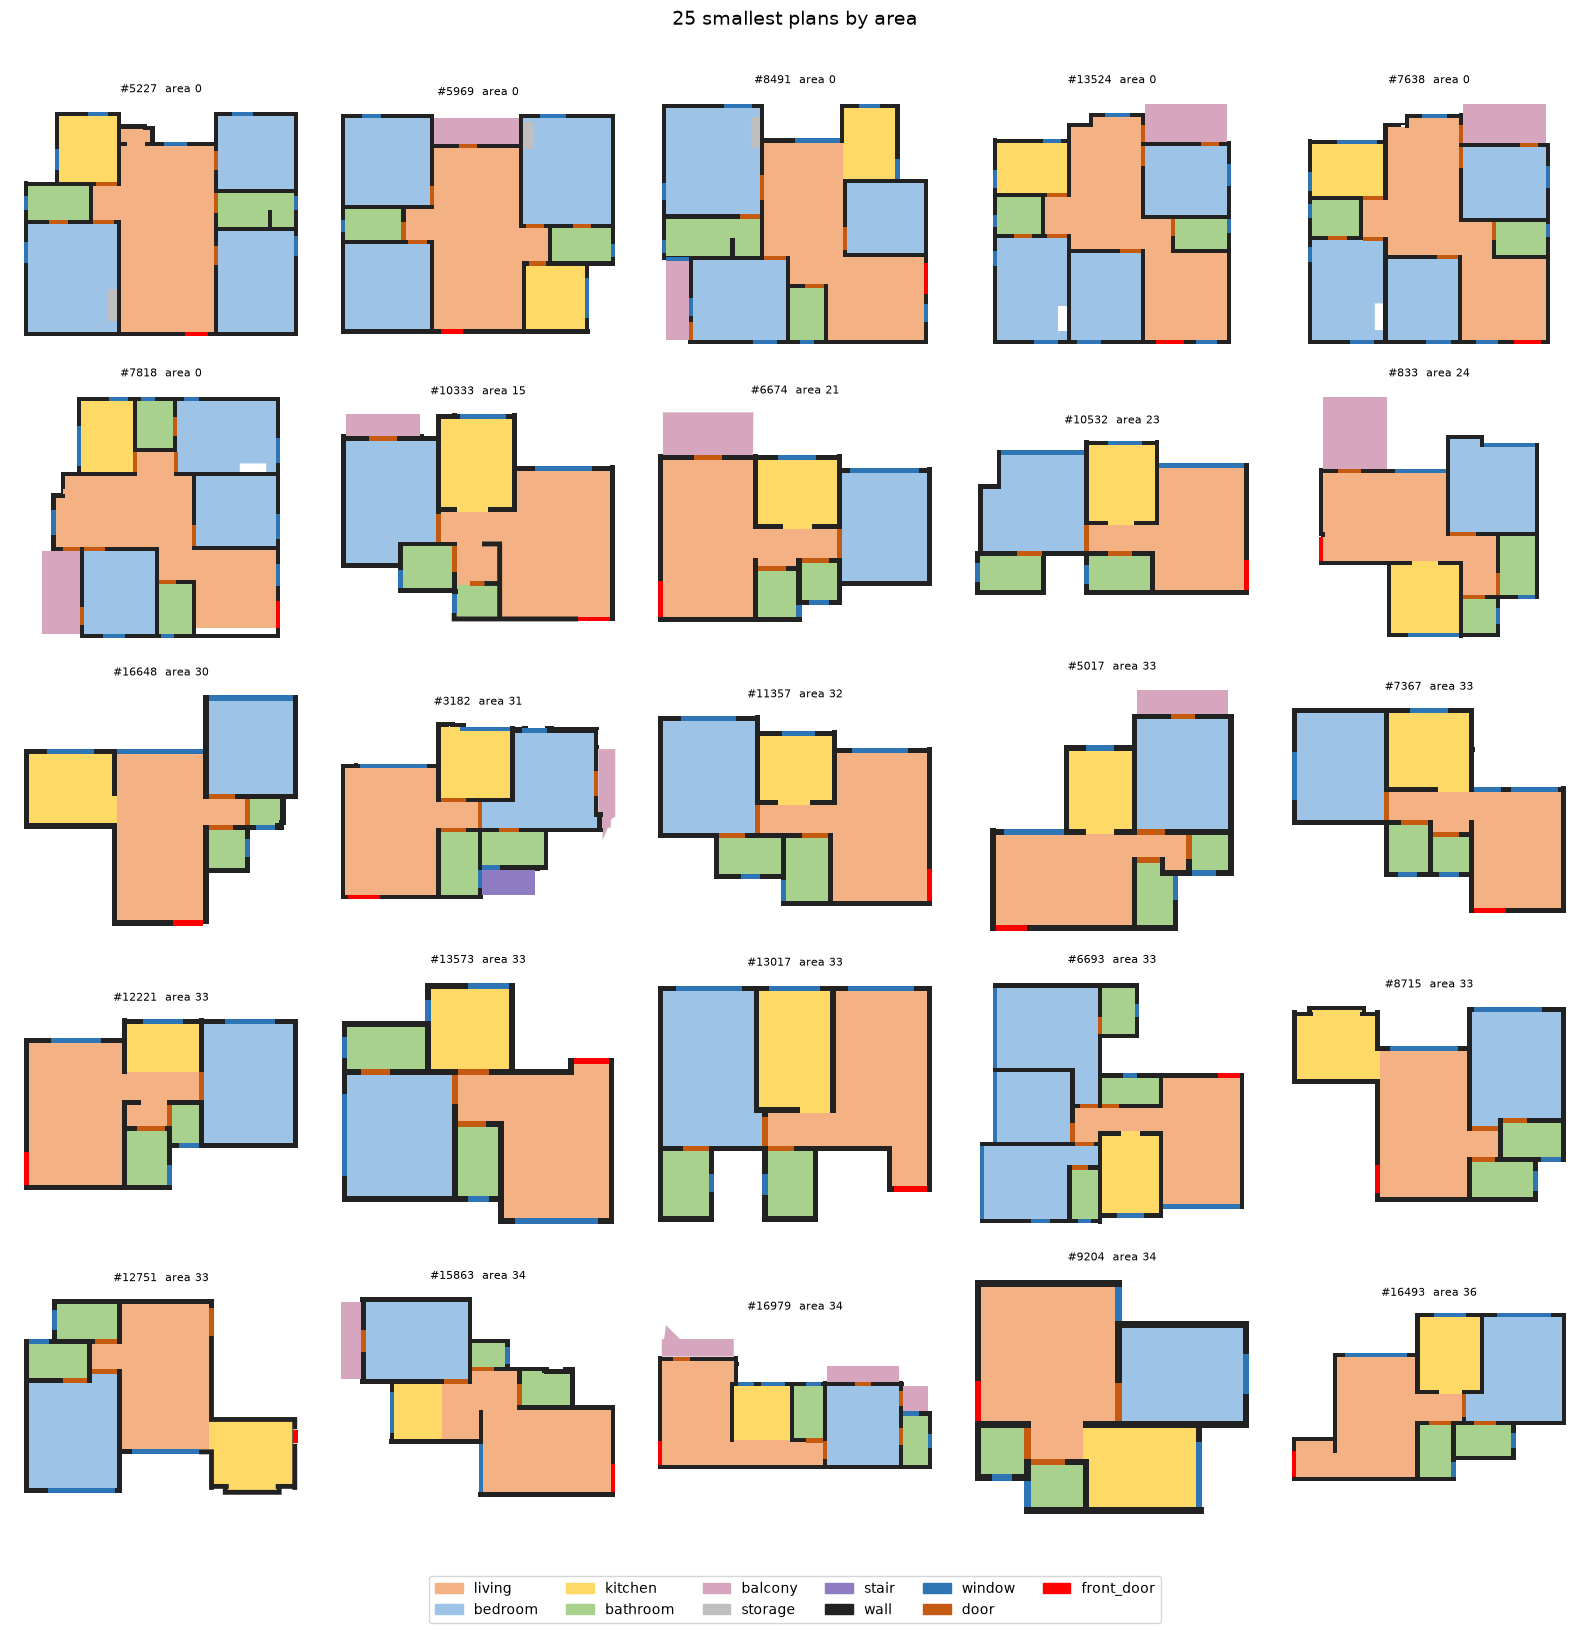

In [19]:
smallest = df.nsmallest(25, "area")["idx"].tolist()
print(df.nsmallest(25, "area")[["idx", "area", "n_rooms"]].to_string(index=False))
show_list(smallest, "25 smallest plans by area")

In [20]:
ROOMS = ["living", "bedroom", "kitchen", "bathroom", "storage", "stair"]

def shape_area(p, key):
    g = p.get(key)
    if g is None or not hasattr(g, "area") or g.is_empty:
        return 0.0
    return g.area

df["inner_shape_area"] = [shape_area(p, "inner") for p in plans]
df["rooms_shape_area"] = [sum(shape_area(p, k) for k in ROOMS) for p in plans]

good = df[(df.net_area > 0) & (df.net_area <= df.area)]
print("Plans where net_area looks correct:", len(good))

print("\nOption 1: net_area vs all rooms added up")
print((good.net_area / good.rooms_shape_area).describe().round(3))

print("\nOption 2: net_area vs indoor outline")
print((good.net_area / good.inner_shape_area).describe().round(3))

print("\n'area' vs indoor outline (to check the units)")
print((df.area / df.inner_shape_area).describe().round(3))

Plans where net_area looks correct: 9746

Option 1: net_area vs all rooms added up
count    9746.000
mean        0.003
std         0.002
min         0.000
25%         0.002
50%         0.002
75%         0.003
max         0.025
dtype: float64

Option 2: net_area vs indoor outline
count    9746.000
mean        0.002
std         0.002
min         0.000
25%         0.002
50%         0.002
75%         0.003
max         0.021
dtype: float64

'area' vs indoor outline (to check the units)
count    17000.000
mean         0.003
std          0.002
min          0.000
25%          0.002
50%          0.003
75%          0.004
max          0.028
dtype: float64


In [21]:
df["net_area_est"] = df.area * df.rooms_shape_area / df.inner_shape_area

good = df[(df.net_area > 0) & (df.net_area <= df.area)]
ratio = good.net_area / good.net_area_est

print("Real net_area ÷ our estimate, on the good plans:")
print(ratio.describe().round(3))
print("\nShare of good plans where our estimate is within 10%:",
      f"{((ratio > 0.9) & (ratio < 1.1)).mean():.0%}")

Real net_area ÷ our estimate, on the good plans:
count    9746.000
mean        0.659
std         0.242
min         0.001
25%         0.628
50%         0.731
75%         0.798
max         1.876
dtype: float64

Share of good plans where our estimate is within 10%: 5%


In [22]:
df["room_share"] = (df.rooms_shape_area / df.inner_shape_area).round(3)
df = df.drop(columns=["net_area", "net_area_est"])

print(df[["area", "room_share"]].describe().round(2))

           area  room_share
count  17000.00    17000.00
mean     120.69        0.97
std       55.24        0.03
min        0.09        0.40
25%       87.14        0.96
50%      109.63        0.97
75%      140.77        0.97
max      712.94        1.67


Rooms overlap (room_share > 1.05): 159
Big gaps      (room_share < 0.85): 55
Of these, also have broken shapes: 41


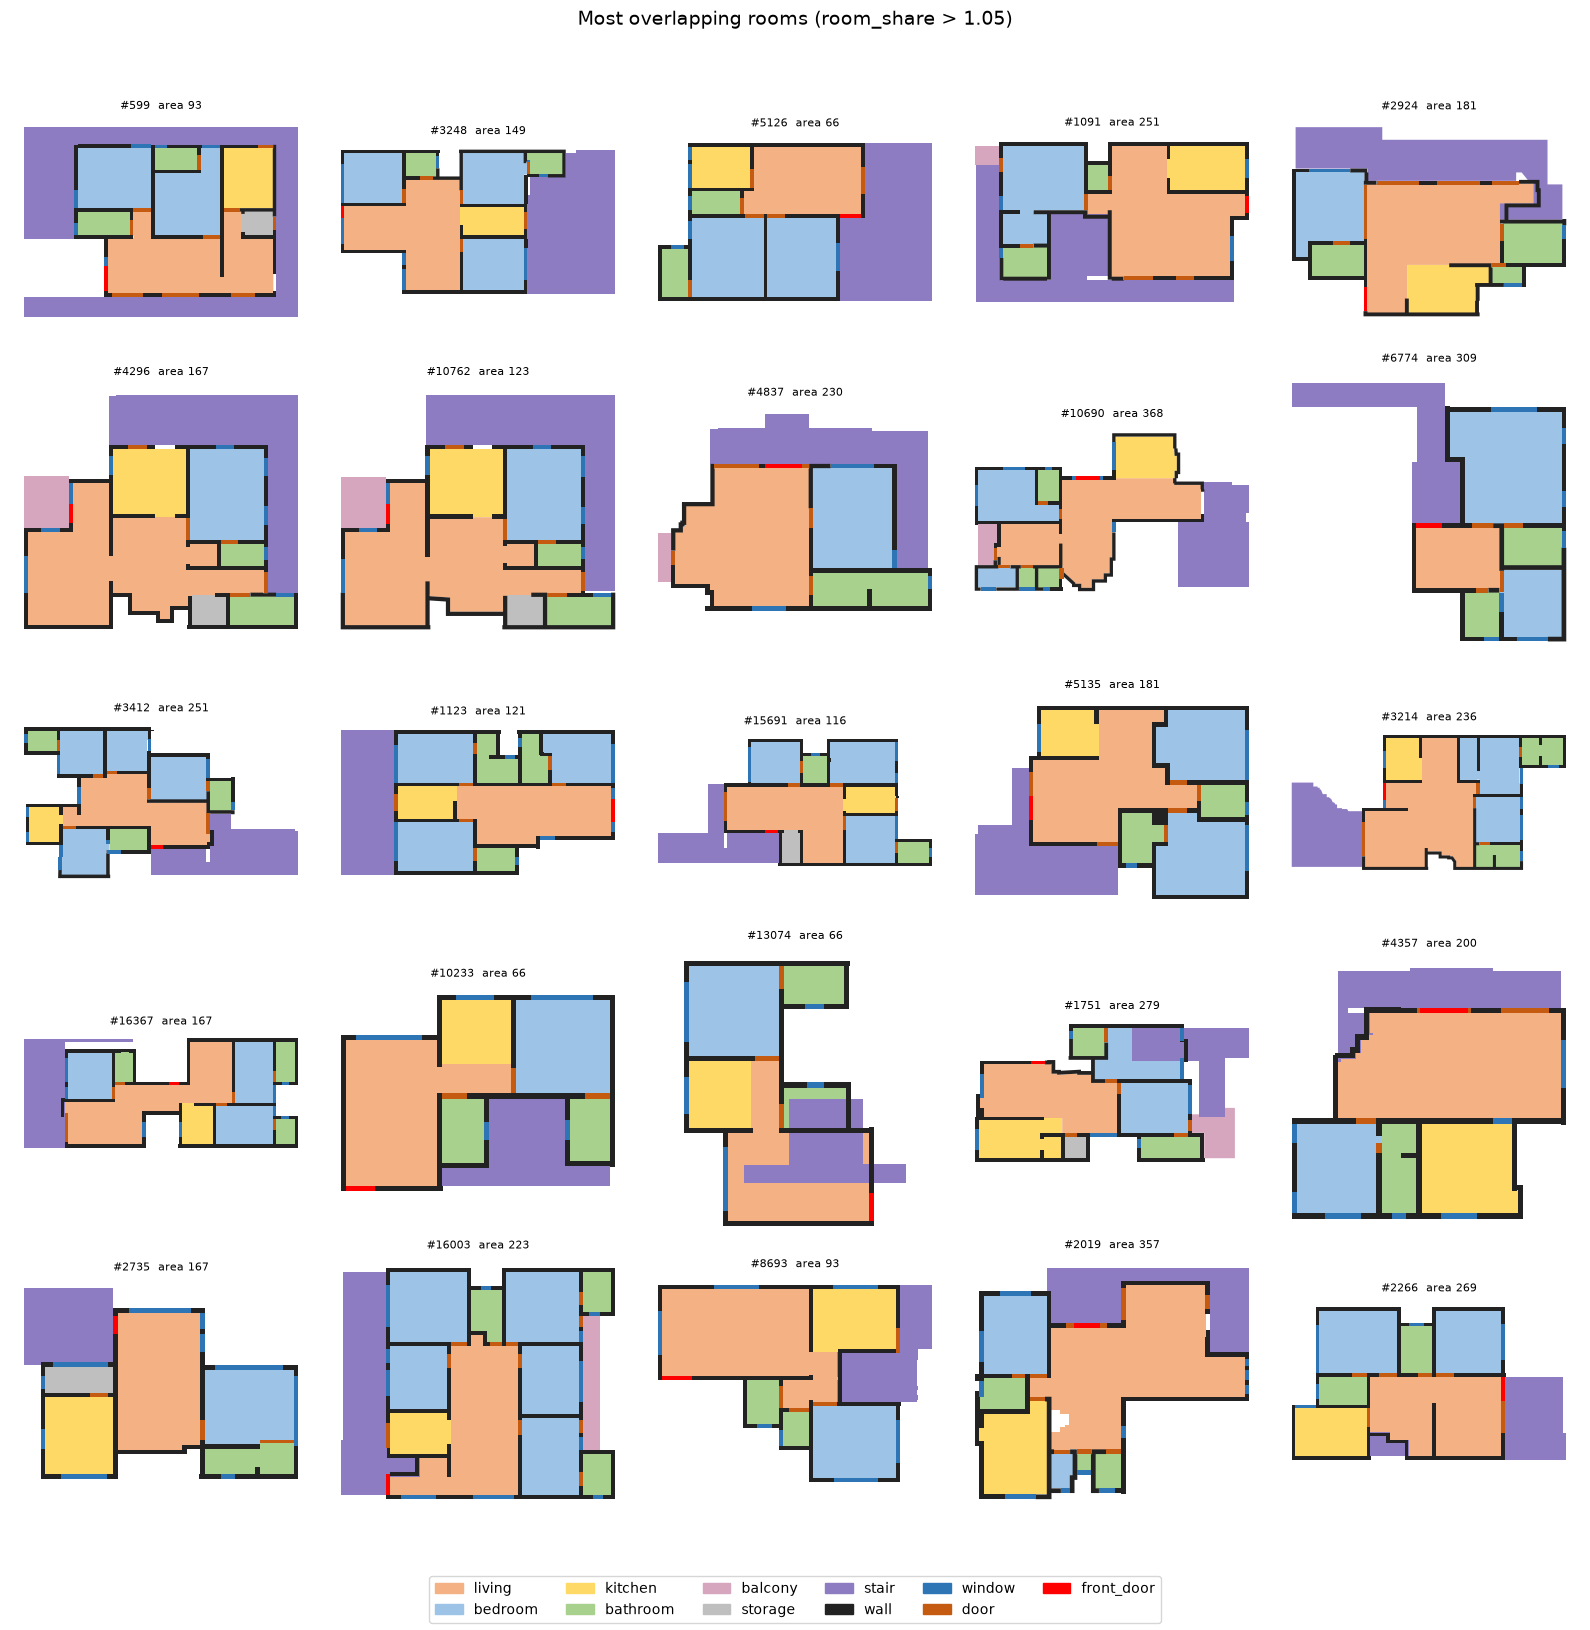

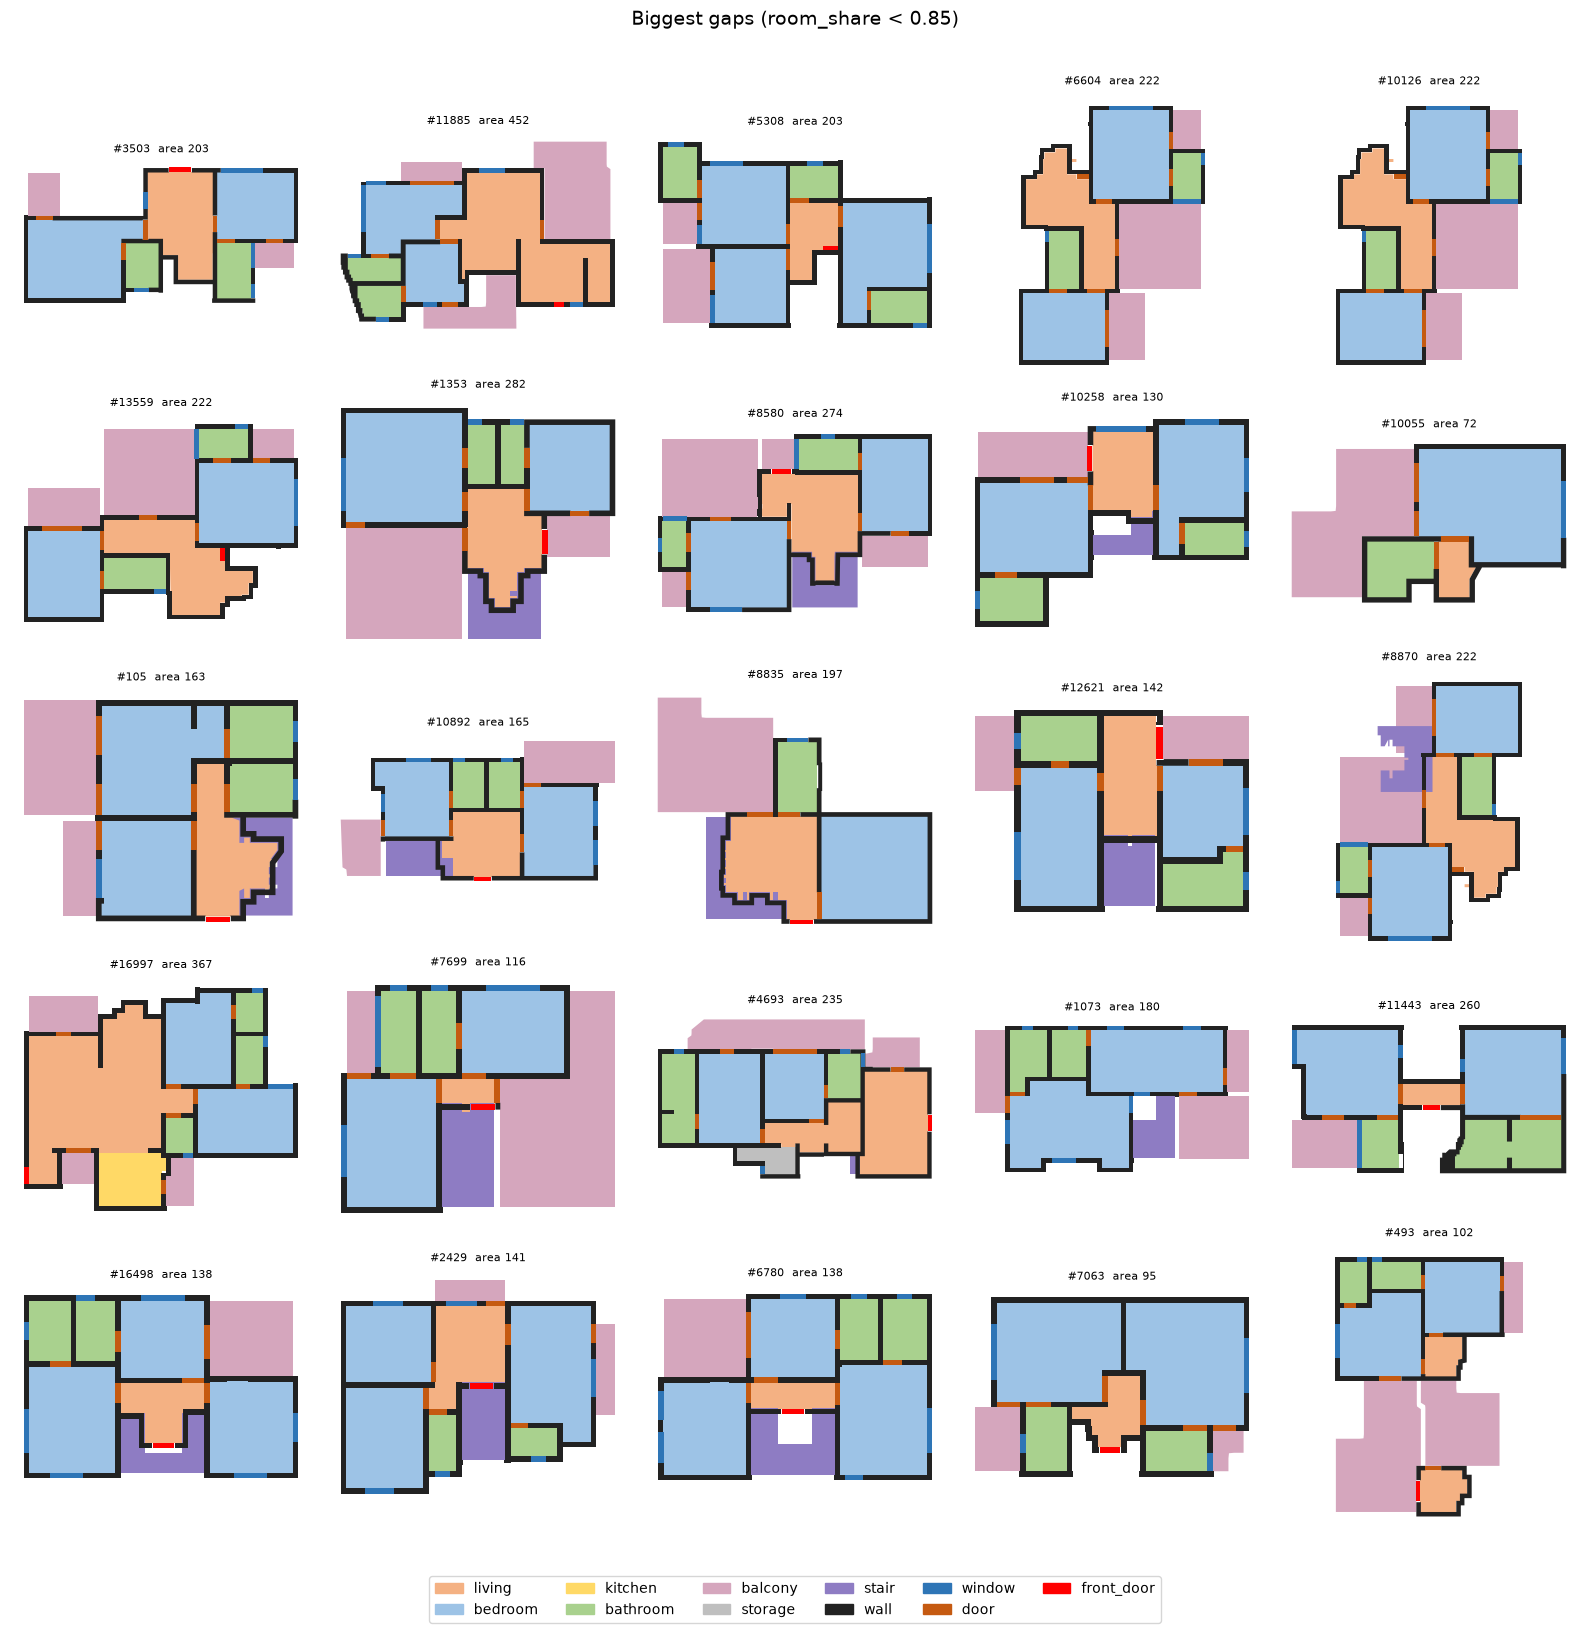

In [23]:
overlap = df.loc[df.room_share > 1.05, "idx"].tolist()
gaps    = df.loc[df.room_share < 0.85, "idx"].tolist()

print("Rooms overlap (room_share > 1.05):", len(overlap))
print("Big gaps      (room_share < 0.85):", len(gaps))
print("Of these, also have broken shapes:",
      len(set(overlap + gaps) & set(broken_idx)))

show_list(sorted(overlap, key=lambda i: -df.room_share[i])[:25],
          "Most overlapping rooms (room_share > 1.05)")
show_list(sorted(gaps, key=lambda i: df.room_share[i])[:25],
          "Biggest gaps (room_share < 0.85)")

In [24]:
# --- Test 1: is the 'stair' group a separate set of plans? ---
stair_set = {i for i, p in enumerate(plans) if has(p, "stair")}
sqft_set  = {i for i, p in enumerate(plans) if "area_change_sqft" in p}
print("Plans with 'stair':", len(stair_set),
      "| with 'area_change_sqft':", len(sqft_set),
      "| BOTH:", len(stair_set & sqft_set))
print("Overlap plans that have 'stair':", len(set(overlap) & stair_set), "of", len(overlap))

# --- Test 2: do the gaps disappear if we count balconies too? ---
df["balcony_shape_area"] = [shape_area(p, "balcony") for p in plans]
df["share_with_balcony"] = (df.rooms_shape_area + df.balcony_shape_area) / df.inner_shape_area

gap_df = df[df.idx.isin(gaps)]
print("\nGap plans:", len(gap_df))
print("  room_share without balcony (median):", round(gap_df.room_share.median(), 2))
print("  room_share WITH balcony    (median):", round(gap_df.share_with_balcony.median(), 2))
print("  Gap plans that are also no-kitchen: ", len(set(gaps) & kitchen_in_living))

Plans with 'stair': 685 | with 'area_change_sqft': 683 | BOTH: 27
Overlap plans that have 'stair': 147 of 159

Gap plans: 55
  room_share without balcony (median): 0.53
  room_share WITH balcony    (median): 0.65
  Gap plans that are also no-kitchen:  39


In [25]:
stair_overlap = set(overlap)   # 'stair' shapes drawn outside/over the building
room_gaps     = set(gaps)      # parts of the home have no room label

df["stair_overlap"] = df["idx"].isin(stair_overlap)
df["room_gaps"]     = df["idx"].isin(room_gaps)

tags = ["kitchen_in_living", "no_window", "no_front_door", "stair_overlap", "room_gaps"]
print("Plans per tag:")
print(df[tags].sum())
print("\nPlans with at least one tag:", df[tags].any(axis=1).sum(), "of", len(df))
print("Plans with NO tag (perfectly clean):", (~df[tags].any(axis=1)).sum())

Plans per tag:
kitchen_in_living    125
no_window             51
no_front_door          5
stair_overlap        159
room_gaps             55
dtype: int64

Plans with at least one tag: 338 of 17000
Plans with NO tag (perfectly clean): 16662


### Finding 4: Overlapping rooms and unlabelled space
- `stair_overlap` (159 plans): rooms add up to more than the home; 147 of them have
  'stair' shapes drawn outside or across the building, so the stair label is unreliable there.
- `room_gaps` (55 plans): rooms cover only ~53% of the home, even counting balconies;
  39 of them are also no-kitchen plans, so part of the home has no room label.
- **Decision:** kept, both tagged.

**Correction to Finding 1:** the "upper floor of a house" explanation relied on
'stair' meaning a real staircase. Finding 4 shows it often doesn't, so the
main explanation for no-kitchen plans is the kitchen being labelled as living.

Plans with broken shapes: 862

Which parts are broken (part: number of plans):
  window       399
  door         364
  land         111
  bedroom      7
  bathroom     5


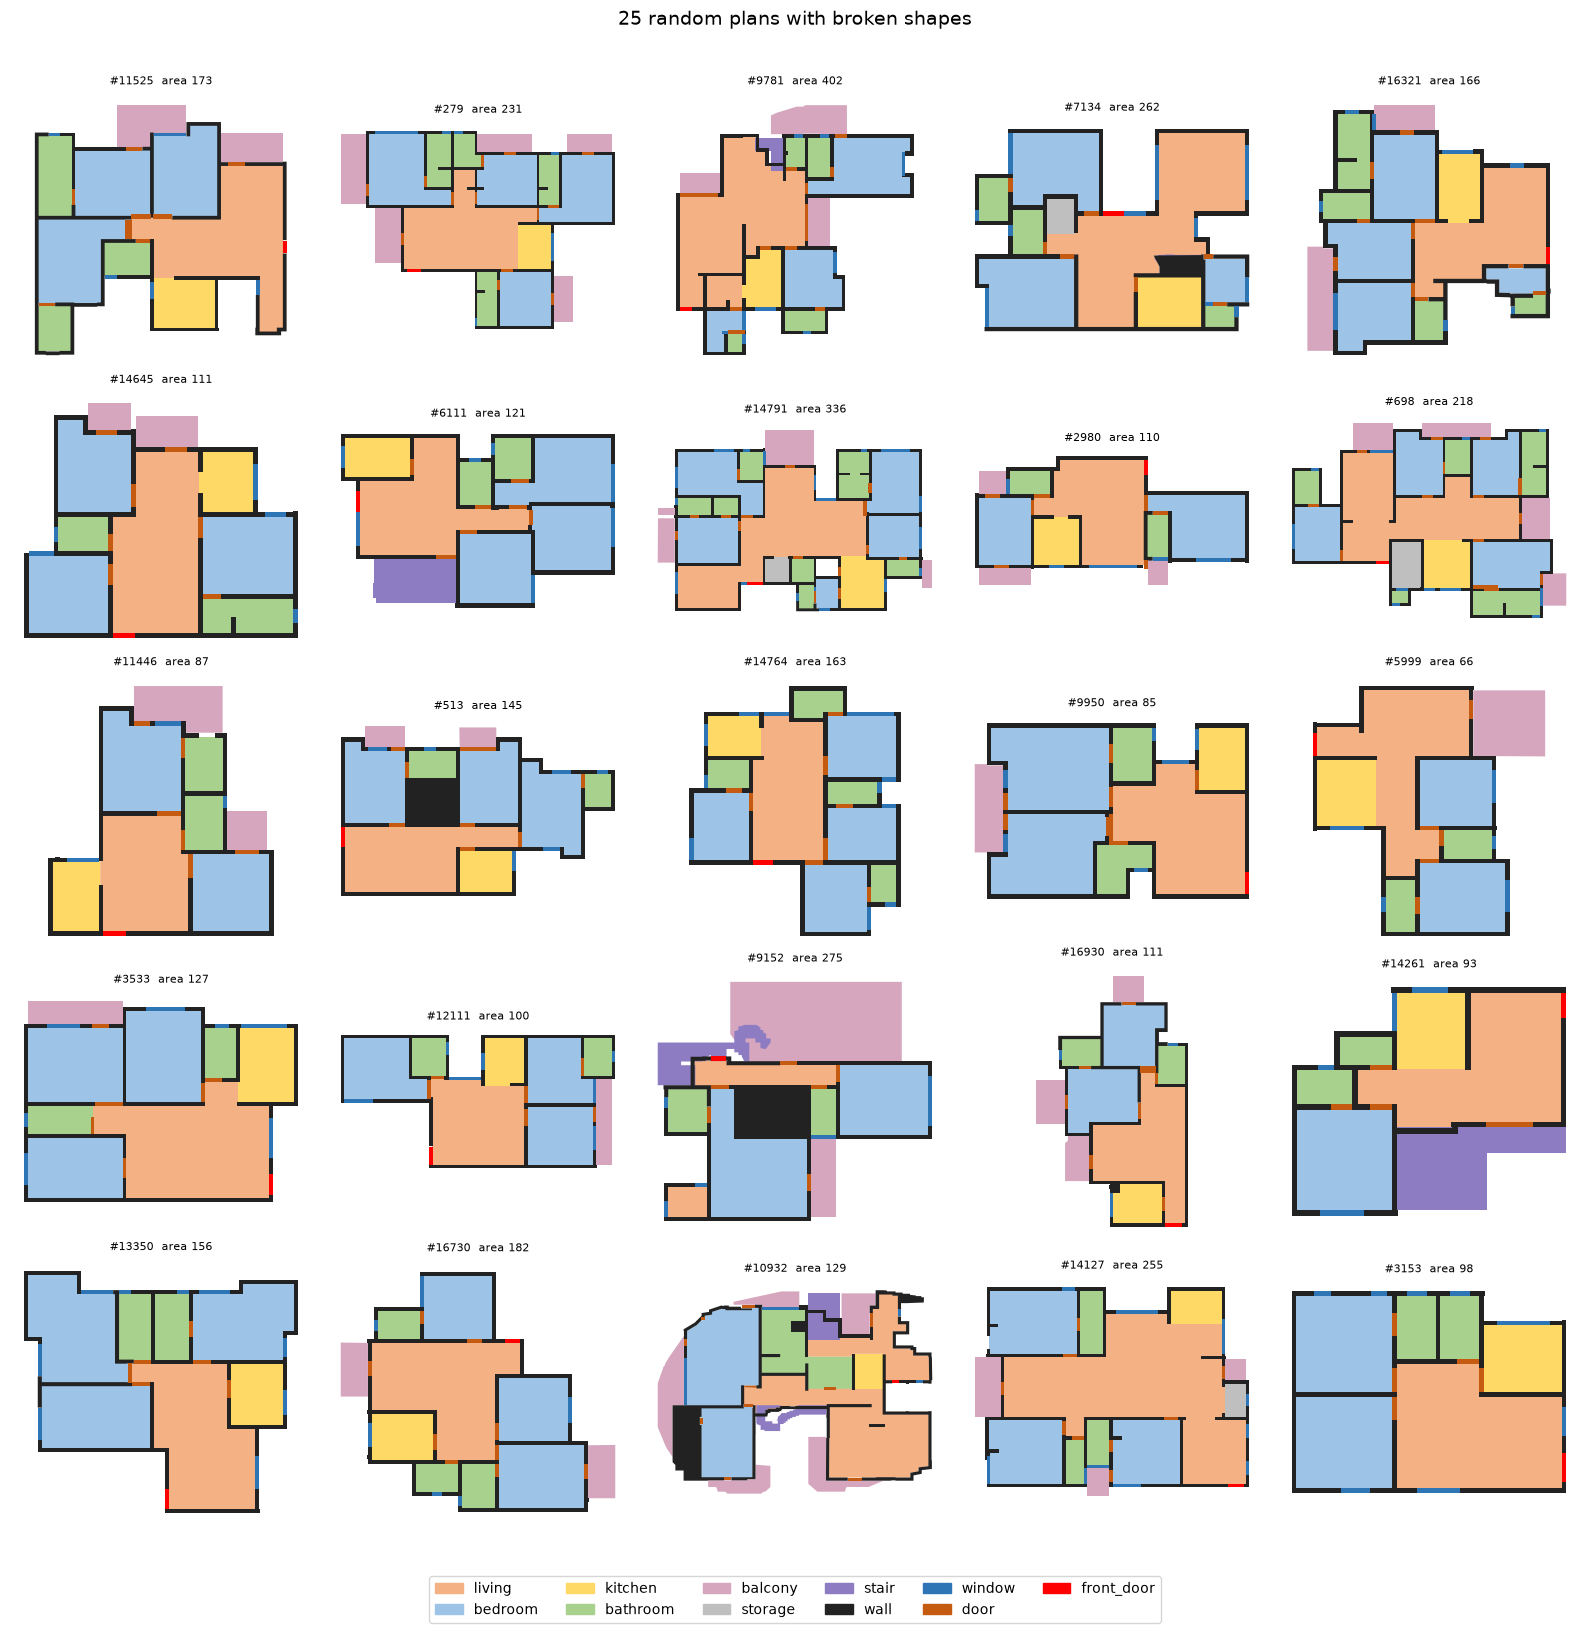

In [26]:
from collections import Counter

broken_idx, broken_parts = [], Counter()
for i, p in enumerate(plans):
    bad = [k for k, g in p.items()
           if hasattr(g, "is_valid") and not g.is_empty and not g.is_valid]
    if bad:
        broken_idx.append(i)
        broken_parts.update(bad)

print("Plans with broken shapes:", len(broken_idx))
print("\nWhich parts are broken (part: number of plans):")
for part, n in broken_parts.most_common():
    print(f"  {part:12} {n}")

show_list(random.sample(broken_idx, 25), "25 random plans with broken shapes")

In [27]:
from shapely.validation import make_valid
from shapely.ops import unary_union

def repair(g):
    """Fix an invalid shape, keeping only its area parts (no stray lines)."""
    fixed = make_valid(g)
    if fixed.geom_type in ("Polygon", "MultiPolygon"):
        return fixed
    polys = [x for x in getattr(fixed, "geoms", [])
             if x.geom_type in ("Polygon", "MultiPolygon")]
    return unary_union(polys) if polys else g

# DRY RUN: repair copies only, nothing in `plans` is changed
fixed_ok, still_bad, area_changes = 0, [], []
for i in broken_idx:
    for k, g in plans[i].items():
        if hasattr(g, "is_valid") and not g.is_empty and not g.is_valid:
            r = repair(g)
            if r.is_valid:
                fixed_ok += 1
                area_changes.append(abs(r.area - g.area) / max(g.area, 1e-9))
            else:
                still_bad.append((i, k))

print("Broken shapes the repair fixes:", fixed_ok)
print("Shapes still broken after repair:", len(still_bad))
print("Median size change from repair:", f"{pd.Series(area_changes).median():.2%}")
print("Repairs that change size by more than 5%:",
      sum(c > 0.05 for c in area_changes))

Broken shapes the repair fixes: 886
Shapes still broken after repair: 0
Median size change from repair: 0.00%
Repairs that change size by more than 5%: 178


In [28]:
rows_fix = []
for i in broken_idx:
    for k, g in plans[i].items():
        if hasattr(g, "is_valid") and not g.is_empty and not g.is_valid:
            r = repair(g)
            change = abs(r.area - g.area) / max(g.area, 1e-9)
            rows_fix.append({"idx": i, "part": k, "change": change})

fix_df = pd.DataFrame(rows_fix)
big = fix_df[fix_df.change > 0.05]

print("Repairs changing size >5%, by part:")
print(big.part.value_counts())
print("\nRoom shapes changed >5%:")
rooms_changed = big[big.part.isin(["bedroom", "bathroom", "kitchen", "living"])]
print(rooms_changed.to_string(index=False) if len(rooms_changed) else "  none")

Repairs changing size >5%, by part:
part
land      99
door      57
window    22
Name: count, dtype: int64

Room shapes changed >5%:
  none


In [29]:
repaired = 0
for i in broken_idx:
    for k, g in list(plans[i].items()):
        if hasattr(g, "is_valid") and not g.is_empty and not g.is_valid:
            plans[i][k] = repair(g)
            repaired += 1

df["shapes_repaired"] = df["idx"].isin(broken_idx)

still_broken = sum(
    1 for p in plans for g in p.values()
    if hasattr(g, "is_valid") and not g.is_empty and not g.is_valid
)
print("Shapes repaired:            ", repaired)
print("Plans tagged shapes_repaired:", df.shapes_repaired.sum())
print("Broken shapes left in data: ", still_broken)

Shapes repaired:             886
Plans tagged shapes_repaired: 862
Broken shapes left in data:  0


### Finding 5: Invalid shapes (862 plans)
- Broken parts were mostly windows (399), doors (364) and land (111); only 12 room shapes.
- Repaired with shapely `make_valid`: all 886 shapes fixed, median size change 0.00%.
- The 178 repairs that changed size by more than 5% were all land, doors or windows
  (overlapping strips merged); no room shape changed by more than 5%.
- **Decision:** repaired, and tagged as `shapes_repaired`.

Plans with no bedroom: [5636, 14965, 15300]


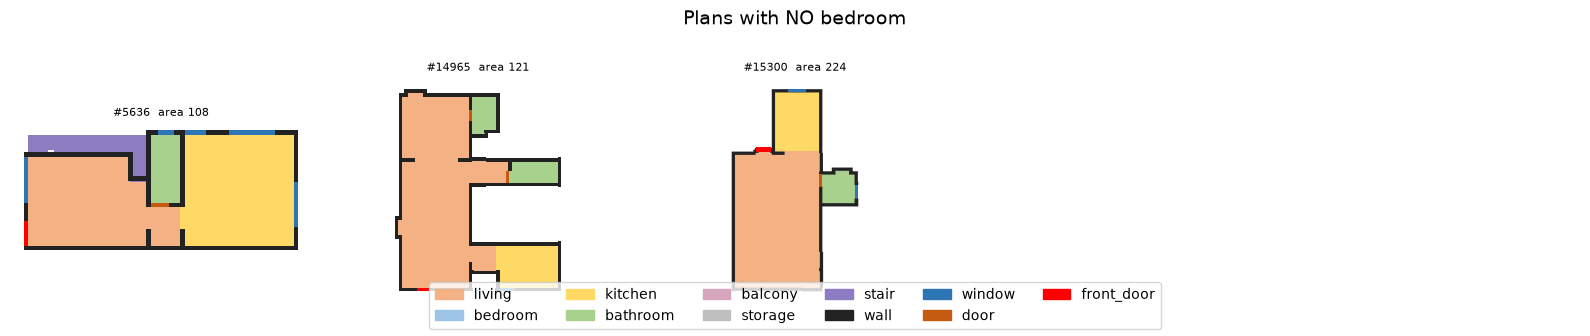

  idx      area  n_rooms  room_share
 5227  0.092903        9       0.963
 5969  0.185806       10       0.965
 8491  0.278709       10       0.964
13524  0.371612        9       0.947
 7638  0.464515        9       0.949
 7818  0.464515        9       0.939
10333 14.841113        7       0.986
 6674 20.903175        7       0.977
10532 23.445381        6       0.977
  833 24.396267        7       0.981
16648 30.438829        6       0.977
 3182 30.641628        8       1.003
11357 32.051535        6       0.979
 5017 32.516050        7       0.965
 7367 32.516050        6       0.978
12221 32.516050        6       0.977
13573 32.533769        6       0.962
13017 32.894087        6       0.984
 6693 32.988154        9       0.962
 8715 33.168389        6       0.976
12751 33.168389        6       0.976
15863 34.002498        7       0.978
16979 34.046969        9       0.976
 9204 34.188304        6       0.964
16493 36.080951        6       0.974


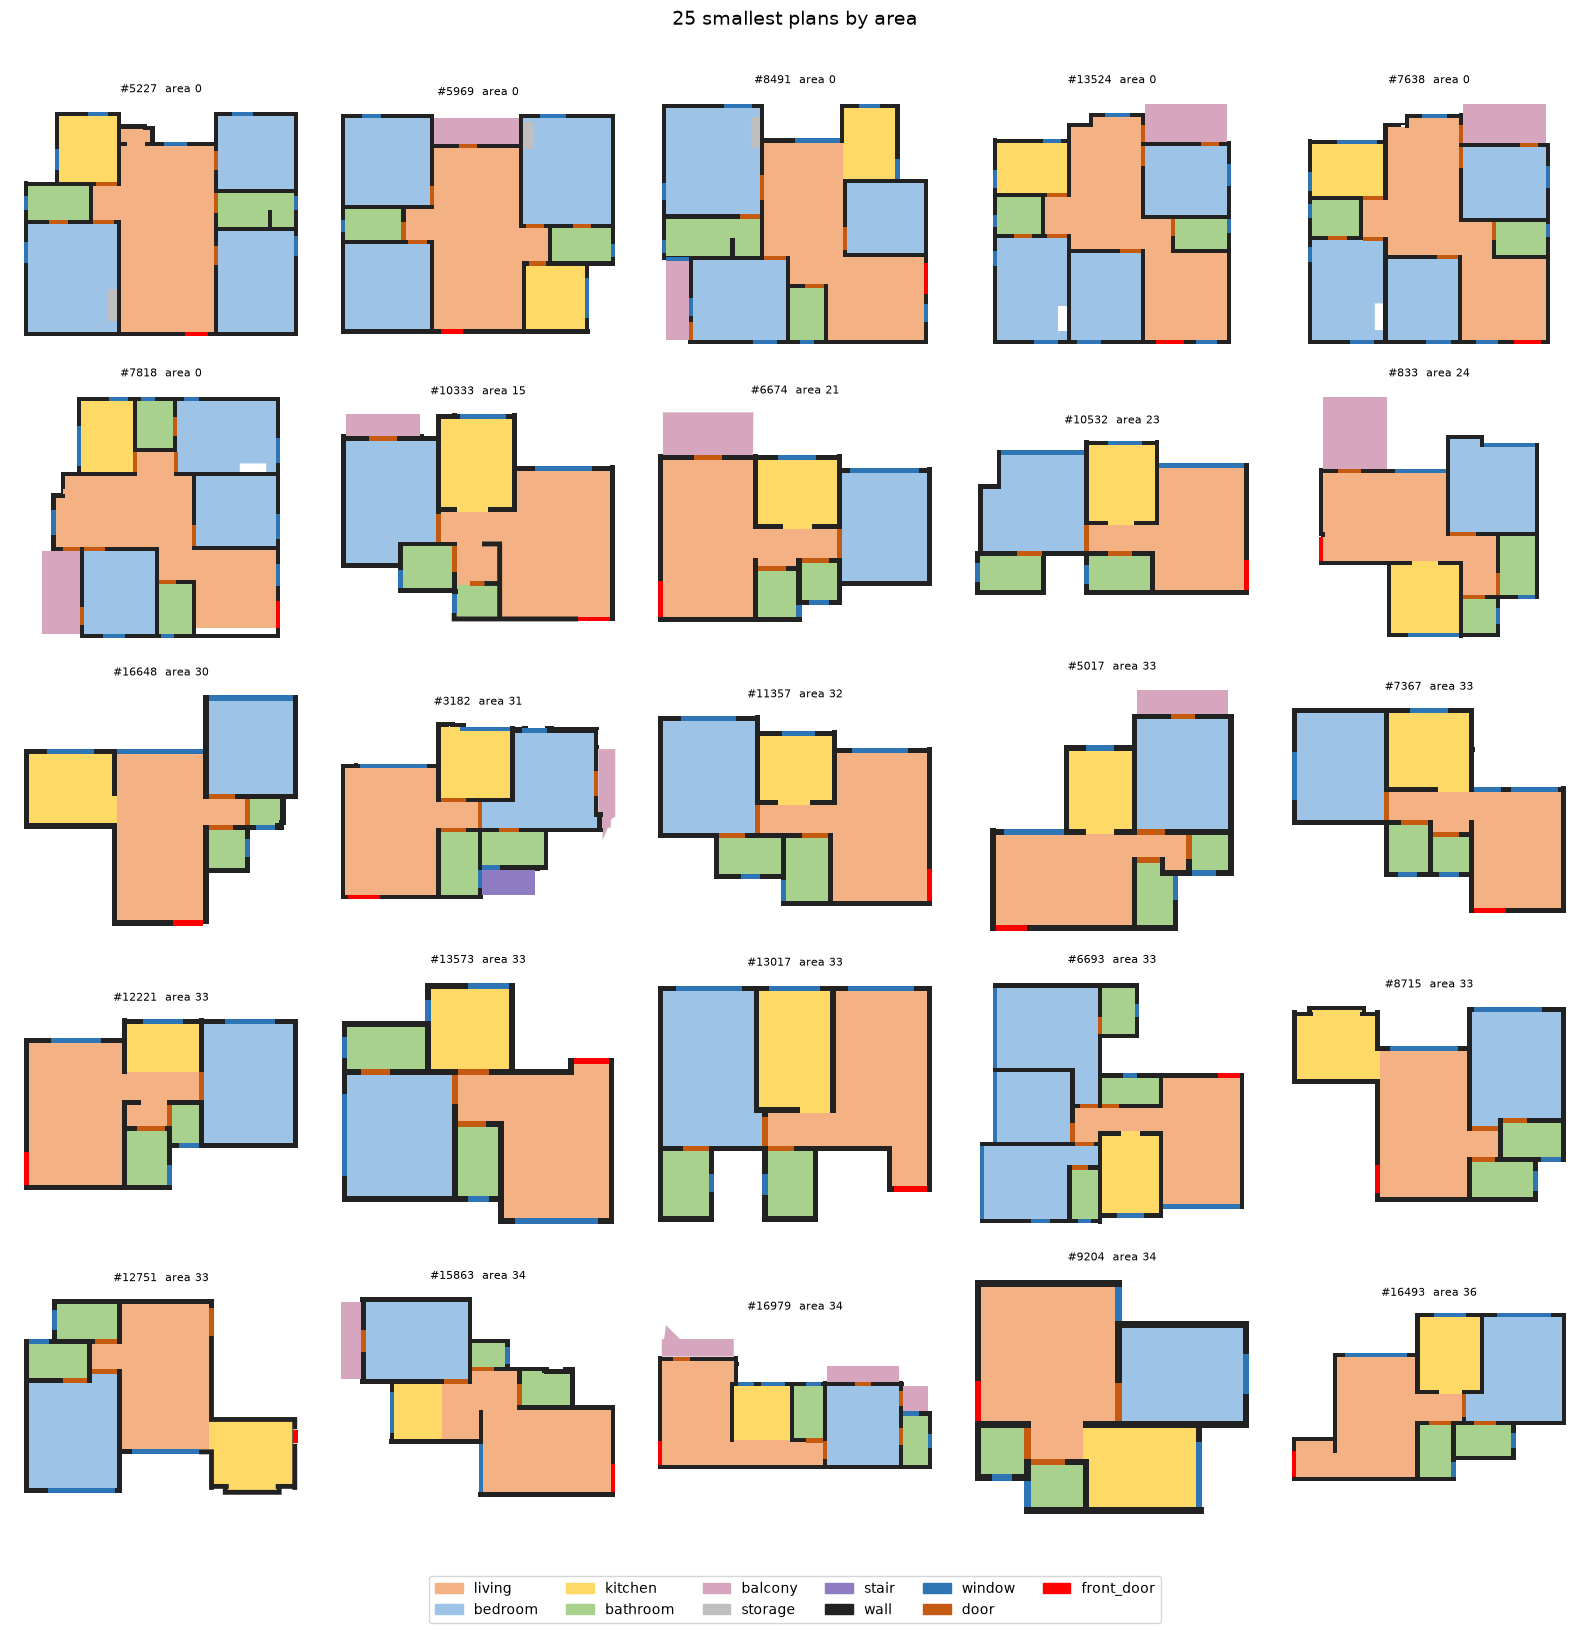

In [30]:
print("Plans with no bedroom:", suspects["bedroom"])
show_list(suspects["bedroom"], "Plans with NO bedroom")

smallest = df.nsmallest(25, "area")
print(smallest[["idx", "area", "n_rooms", "room_share"]].to_string(index=False))
show_list(smallest["idx"].tolist(), "25 smallest plans by area")

In [31]:
import numpy as np

no_bedroom = set(suspects["bedroom"])
bad_area   = set(df.loc[df.area < 1, "idx"])

df["no_bedroom"] = df["idx"].isin(no_bedroom)
df["bad_area"]   = df["idx"].isin(bad_area)
df.loc[df.bad_area, "area"] = np.nan      # wrong value → unknown

print("Tagged no_bedroom:", sorted(no_bedroom))
print("Tagged bad_area:  ", sorted(bad_area))
print("\nArea after fix:")
print(df.area.describe().round(1))

Tagged no_bedroom: [5636, 14965, 15300]
Tagged bad_area:   [5227, 5969, 7638, 7818, 8491, 13524]

Area after fix:
count    16994.0
mean       120.7
std         55.2
min         14.8
25%         87.2
50%        109.6
75%        140.8
max        712.9
Name: area, dtype: float64


### Finding 6: No bedroom, and impossible areas
- `no_bedroom` (3 plans): living + kitchen + bathroom only, i.e. studio / open-plan homes. Kept, tagged.
- `bad_area` (6 plans): area recorded as exactly 1–5 × 0.0929 m² (= 1–5 sq ft), a unit bug.
  The drawings are normal (9–10 rooms). Kept, tagged, and area set to unknown (NaN).

In [32]:
TAGS = ["kitchen_in_living", "no_window", "no_front_door", "stair_overlap",
        "room_gaps", "shapes_repaired", "no_bedroom", "bad_area"]

records = df.to_dict("records")       # one row per plan, same order as `plans`
clean = []
for p, r in zip(plans, records):
    q = dict(p)                        # copy the plan
    q.pop("net_area", None)            # drop the unreliable column
    q["area"] = r["area"]              # NaN for the 6 bad_area plans
    q["room_share"] = r["room_share"]
    q["tags"] = [t for t in TAGS if r[t]]
    clean.append(q)

with open(r"D:\Resplan\ResPlan_clean.pkl", "wb") as f:
    pickle.dump(clean, f, protocol=pickle.HIGHEST_PROTOCOL)

df[["idx", "id", "area", "n_rooms", "room_share"] + TAGS].to_csv(
    "plan_tags.csv", index=False)

print("Saved", len(clean), "plans to D:\\Resplan\\ResPlan_clean.pkl")
print("Saved tag table to 01_autoencoder\\plan_tags.csv")

Saved 17000 plans to D:\Resplan\ResPlan_clean.pkl
Saved tag table to 01_autoencoder\plan_tags.csv


In [33]:
with open(r"D:\Resplan\ResPlan_clean.pkl", "rb") as f:
    check = pickle.load(f)

print("Plans in clean file:   ", len(check))
print("Any net_area left?     ", any("net_area" in p for p in check))
print("Broken shapes left:    ", sum(1 for p in check for g in p.values()
                                     if hasattr(g, "is_valid") and not g.is_empty and not g.is_valid))
print("Plans with no tags:    ", sum(1 for p in check if not p["tags"]))
print("Example tags, plan 5227:", check[5227]["tags"], "| area:", check[5227]["area"])

Plans in clean file:    17000
Any net_area left?      False
Broken shapes left:     0
Plans with no tags:     15840
Example tags, plan 5227: ['bad_area'] | area: nan
